# Phase 5 — Legal Statute Identification (LSI): Experiment 1 = Phase 1 Encoder + Full Fine-Tuning

**Goal.** Find (with short 2-epoch experiments) the best *recipe* for multi-label statute identification with the Phase 1 bidirectional-GQA encoder under **full fine-tuning**, then train that recipe on the full training set (early stopping on dev), save the final `.pt`, and write the competition `submission.json`.

**Experiment protocol (greedy / coordinate ascent, every run starts from the Phase 1 weights):**

| Stage | What is compared | Runs | Cost |
|---|---|---|---|
| S0 | Encoder learning rate (2e-5 / 5e-5 / 1e-4) | 3 | train |
| S1 | Loss + class weighting: BCE / pos-weighted BCE / focal / asymmetric loss (ASL) | 4 | train |
| S2 | Pooling + classification head: mean / BOS / attention-pool / mean+max MLP / label-attention (LAAT) | 5 | train |
| S3 | Long-document representation: head-512 / head+tail (255+255) / cue-selected context / 2-view chunk models, + chunk-logit aggregation | 6 | train |
| S4 | Post-hoc (no training): global vs per-label vs shrunk thresholds, top-1 fallback, temperature / Platt calibration, label co-occurrence stacker | — | free |
| Final | Best recipe, full train set, early stopping on dev, saves `.pt` + `submission.json` | 1 | long |

Things decided **without** experiments (cheap, well-established, or trivial): classifier-bias initialised to label prior log-odds, layer-wise LR decay (0.92), linear warm-up + decay, AMP fp16, grad-clip 1.0, whitespace-run collapsing in the tokenizer, de-duplicated sorted integer outputs.

Every experiment stores its dev logits + metrics to disk, so if the Kaggle session dies you can re-run the notebook and finished experiments are skipped.

## 0. Configuration (edit this cell only)

In [1]:
import os, sys, re, gc, json, math, time, heapq, random, subprocess, warnings
from pathlib import Path
from dataclasses import dataclass, fields, asdict
from collections import Counter, OrderedDict

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------------- environment -----------------------------
ON_KAGGLE = Path("/kaggle").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("./lsi_work")
WORK.mkdir(parents=True, exist_ok=True)

# Phase 1 artifacts (set exact paths; leave "" for auto-discovery under /kaggle/input or WORK)
PHASE1_CHECKPOINT_OVERRIDE = "/kaggle/input/datasets/vishwaspathania/encoder-phase1/best_encoder_mlm.pt"
PHASE1_TOKENIZER_OVERRIDE  = "/kaggle/input/datasets/vishwaspathania/tokenizer-phase5/legal_bpe_a1_50k_final.json"

# Data: either point to a local folder holding train.json/dev.json/test.json, or download from HF.
LOCAL_DATA_DIR = ""          # e.g. "/kaggle/input/lsi-data"  (leave "" to download from Hugging Face)
HF_REPO_ID = "Exploration-Lab/CS-781-Capstone"
HF_FILES = {"train": "Phase_5_LSI/Train/train.json",
            "dev":   "Phase_5_LSI/Train/dev.json",
            "test":  "Phase_5_LSI/Test/test.json"}
# The token is read from env HF_TOKEN, then Kaggle Secret "HF_TOKEN", then a prompt. Never hard-code it.

NUM_LABELS = 100
MAX_LEN = 512                 # encoder context (BOS + 510 content + EOS)
CONTENT = MAX_LEN - 2
MAX_DOC_TOKENS = 16_384       # per-document cap when caching (keeps head + last 4096 for very long docs)
TOK_CACHE_VERSION = "v1"

# ----------------------------- experiment budget -----------------------------
EXP_EPOCHS      = 2           # every experiment trains 2 epochs
EXP_TRAIN_DOCS  = 8_000       # random (rare-label topped-up) subset of train used in S0-S3
EXP_DEV_DOCS    = 3_000       # random subset of dev used to score S0-S3
MIN_POS_PER_LABEL_SUBSET = 60 # top-up so rare statutes are present in the experiment subset
EFFECTIVE_BATCH = 32          # documents per optimizer step
SELECTION_TOL   = 0.004       # parsimony rule: among configs within TOL of the best macro-F1, take the cheapest

# Which stages to run (set False to skip and keep BASE defaults)
RUN_S0_LR, RUN_S1_LOSS, RUN_S2_HEAD, RUN_S3_REPR = True, True, True, True

# ----------------------------- final training -----------------------------
FINAL_MAX_EPOCHS   = 10
FINAL_PATIENCE     = 2            # early stopping on dev macro-F1 (global-best-threshold)
FINAL_TIME_BUDGET_H = 8.5         # planned epochs are reduced so the LR schedule completes inside this budget
RESUME_FINAL       = False        # True -> continue an interrupted final run from final_last.pt

SMOKE_TEST = False            # True -> tiny end-to-end dry run (~10-15 min after tokenisation) to verify the whole pipeline
FINAL_TRAIN_DOCS_LIMIT = None # (normally None = all 42,750 training docs)

SEED = 42
BASE = dict(                         # default recipe; stages overwrite fields as they find better ones
    views=("head",), view_agg="tokens", head="mean", loss="bce",
    enc_lr=5e-5, head_lr=1e-3, llrd=0.92, wd=0.01, dropout=0.1, warmup=0.06,
)

if SMOKE_TEST:
    EXP_TRAIN_DOCS, EXP_DEV_DOCS, FINAL_MAX_EPOCHS, FINAL_TRAIN_DOCS_LIMIT, MIN_POS_PER_LABEL_SUBSET = 256, 256, 2, 512, 2
RUN_DIR = WORK / ("lsi_runs_smoke" if SMOKE_TEST else "lsi_runs"); RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = WORK / f"lsi_tok_cache_{TOK_CACHE_VERSION}"; CACHE_DIR.mkdir(parents=True, exist_ok=True)
EXP_STORE = RUN_DIR / "experiments.json"
print("WORK:", WORK.resolve()); print("ON_KAGGLE:", ON_KAGGLE)

WORK: /kaggle/working
ON_KAGGLE: True


## 1. Imports, GPU, seeds

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
try:
    from IPython.display import display
except Exception:
    display = print

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_everything(SEED)

assert torch.cuda.is_available(), "Enable a GPU runtime."
device = torch.device("cuda")
gpu = torch.cuda.get_device_properties(0)
print("GPU:", gpu.name, f"| {gpu.total_memory/1024**3:.1f} GiB | torch {torch.__version__}")

GPU: Tesla T4 | 14.6 GiB | torch 2.11.0+cu128


## 2. Locate / download the Phase 5 data and the Phase 1 artifacts

In [3]:
try:
    import ijson
except ImportError:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ijson"]); import ijson
    except Exception:
        ijson = None

def _get_hf_token():
    tok = os.environ.get("HF_TOKEN", "").strip()
    if not tok:
        try:
            from kaggle_secrets import UserSecretsClient
            tok = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            tok = ""
    if not tok:
        from getpass import getpass
        tok = getpass("Hugging Face token: ")
    return tok

def locate_data():
    paths = {}
    if LOCAL_DATA_DIR:
        for split in HF_FILES:
            p = Path(LOCAL_DATA_DIR) / f"{split}.json"
            if not p.is_file(): raise FileNotFoundError(p)
            paths[split] = p
        return paths
    from huggingface_hub import hf_hub_download
    token = _get_hf_token()
    for split, fn in HF_FILES.items():
        paths[split] = Path(hf_hub_download(repo_id=HF_REPO_ID, repo_type="dataset", filename=fn, token=token))
    return paths

def iter_json_records(path):
    """Yield records from a JSON array (streamed with ijson when available) or JSONL."""
    with open(path, "rb") as f:
        first = b""
        while True:
            ch = f.read(1)
            if not ch: break
            if ch not in b" \t\r\n": first = ch; break
        f.seek(0)
        if first == b"[":
            if ijson is not None:
                yield from ijson.items(f, "item")
            else:
                yield from json.load(f)
        elif first == b"{":
            for line in f:
                line = line.strip()
                if line: yield json.loads(line)
        else:
            raise ValueError(f"Unrecognised JSON layout: {path}")

def find_artifact(filename, override=""):
    if override and Path(override).is_file(): return Path(override).resolve()
    hits = set()
    for root in [Path("/kaggle/input"), WORK, Path(".")]:
        if root.exists(): hits.update(p.resolve() for p in root.rglob(filename) if p.is_file())
    hits = sorted(hits)
    if len(hits) != 1:
        raise FileNotFoundError(f"{filename}: found {len(hits)} candidates {hits}. Set the override path in the config cell.")
    return hits[0]

# Only download when the tokenization cache is missing (so a resumed session does not need the files again).
need_raw = not all((CACHE_DIR / f"{s}_done.flag").exists() for s in ["train", "dev", "test"])
paths = locate_data() if need_raw else {}
PHASE1_CHECKPOINT_PATH = find_artifact("best_encoder_mlm.pt", PHASE1_CHECKPOINT_OVERRIDE)
PHASE1_TOKENIZER_PATH  = find_artifact("legal_bpe_a1_50k_final.json", PHASE1_TOKENIZER_OVERRIDE)
print("data paths :", {k: str(v) for k, v in paths.items()} if paths else "(token cache present, raw files not needed)")
print("checkpoint :", PHASE1_CHECKPOINT_PATH)
print("tokenizer  :", PHASE1_TOKENIZER_PATH)

Hugging Face token:  ········


Phase_5_LSI/Train/train.json: reconstructing file:   0%|          |  0.00B /  299MB            

Phase_5_LSI/Train/train.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Train/dev.json: reconstructing file:   0%|          |  0.00B / 79.4MB            

Phase_5_LSI/Train/dev.json: downloading bytes:           |  0.00B            

Phase_5_LSI/Test/test.json: reconstructing file:   0%|          |  0.00B / 98.1MB            

Phase_5_LSI/Test/test.json: downloading bytes:           |  0.00B            

data paths : {'train': '/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_5_LSI/Train/train.json', 'dev': '/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_5_LSI/Train/dev.json', 'test': '/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/93b0059be756c6c461f3a225de25aabda7d5f84a/Phase_5_LSI/Test/test.json'}
checkpoint : /kaggle/input/datasets/vishwaspathania/encoder-phase1/best_encoder_mlm.pt
tokenizer  : /kaggle/input/datasets/vishwaspathania/tokenizer-phase5/legal_bpe_a1_50k_final.json


## 3. Phase 1 tokenizer (identical A-1 BPE) and the Phase 1 encoder definition

In [4]:
SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]
N_SPECIAL, N_BYTES = 4, 256
BASE_VOCAB = N_SPECIAL + N_BYTES
WORD_RE = re.compile(r"\S+")

class A1BPETokenizer:
    def __init__(self, itos, merges):
        self.itos = list(itos); self.merges = [tuple(m) for m in merges]
        self.vocab_size = len(self.itos)
        self.stoi = {s: i for i, s in enumerate(self.itos)}
        self._byte_to_id = {bytes([b]): N_SPECIAL + b for b in range(256)}
        self._merge_ranks = {pair: r for r, pair in enumerate(self.merges)}

    def _encode_word(self, word):                      # unchanged from Phase 1 / Phase 3
        raw = word.encode("utf-8")
        seq = [self._byte_to_id[bytes([b])] for b in raw]
        if len(seq) < 2 or not self._merge_ranks: return seq
        n = len(seq); prev = [-1] + list(range(n - 1)); nxt = list(range(1, n)) + [-1]
        active = [True] * n; heap = []
        for i in range(n - 1):
            r = self._merge_ranks.get((seq[i], seq[i + 1]))
            if r is not None: heapq.heappush(heap, (r, i, i + 1))
        while heap:
            rank, left, right = heapq.heappop(heap)
            if not active[left] or not active[right]: continue
            if nxt[left] != right or prev[right] != left: continue
            if self._merge_ranks.get((seq[left], seq[right])) != rank: continue
            seq[left] = BASE_VOCAB + rank; active[right] = False
            rn = nxt[right]; nxt[left] = rn
            if rn != -1: prev[rn] = left
            lp = prev[left]
            if lp != -1:
                nr = self._merge_ranks.get((seq[lp], seq[left]))
                if nr is not None: heapq.heappush(heap, (nr, lp, left))
            if rn != -1:
                nr = self._merge_ranks.get((seq[left], seq[rn]))
                if nr is not None: heapq.heappush(heap, (nr, left, rn))
        out, i = [], 0
        while i != -1:
            if active[i]: out.append(seq[i])
            i = nxt[i]
        return out

def load_a1_tokenizer(path):
    with open(path, "r", encoding="utf-8") as f: payload = json.load(f)
    tok = A1BPETokenizer(payload["itos"], payload["merges"])
    assert tok.vocab_size == 50_000 and tok.itos[:4] == SPECIAL_TOKENS
    return tok

phase1_tokenizer = load_a1_tokenizer(PHASE1_TOKENIZER_PATH)
PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
SPACE_ID = N_SPECIAL + 32          # single ASCII space byte token (id 36)
assert (phase1_tokenizer.stoi["<pad>"], phase1_tokenizer.stoi["<s>"], phase1_tokenizer.stoi["</s>"]) == (0, 2, 3)

# ---- Phase 1 checkpoint config + weights (kept on CPU so every experiment restarts from the same weights)
_ckpt = torch.load(PHASE1_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
PHASE1_STATE = {k: v for k, v in _ckpt["model_state_dict"].items()}
_cfg_dict = dict(_ckpt["model_config"]); del _ckpt; gc.collect()

@dataclass
class ModelConfig:
    vocab_size: int = 50_000; d_model: int = 768; n_layers: int = 16; n_heads: int = 12
    n_kv_heads: int = 4; d_ff: int = 2048; max_seq_len: int = 512
    rope_base: float = 10_000.0; rms_norm_eps: float = 1e-6; dropout: float = 0.0

cfg = ModelConfig(**{k: v for k, v in _cfg_dict.items() if k in {f.name for f in fields(ModelConfig)}})
print(cfg)

def build_rope_cache(max_seq_len, d_head, base=10_000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, d_head // 2, dtype=torch.float32) * 2 / d_head))
    freqs = torch.outer(torch.arange(max_seq_len, dtype=torch.float32), inv_freq)
    ang = torch.cat([freqs, freqs], dim=-1)
    return ang.cos(), ang.sin()

def rotate_half(x):
    x1, x2 = torch.chunk(x, 2, dim=-1)
    return torch.cat([-x2, x1], dim=-1)

def apply_rope(x, cos, sin):
    return x * cos.to(x.device, x.dtype)[None, None] + rotate_half(x) * sin.to(x.device, x.dtype)[None, None]

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        dt = x.dtype; xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight.float()).to(dt)

class SwiGLU(nn.Module):
    def __init__(self, d, ff):
        super().__init__()
        self.gate_proj = nn.Linear(d, ff, bias=False); self.up_proj = nn.Linear(d, ff, bias=False)
        self.down_proj = nn.Linear(ff, d, bias=False)
    def forward(self, x): return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))

class BidirectionalGQAAttention(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.d_model, self.n_heads, self.n_kv_heads = c.d_model, c.n_heads, c.n_kv_heads
        self.head_dim = c.d_model // c.n_heads; self.n_rep = c.n_heads // c.n_kv_heads; self.max_seq_len = c.max_seq_len
        self.q_proj = nn.Linear(c.d_model, c.n_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(c.d_model, c.n_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(c.d_model, c.n_kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(c.d_model, c.d_model, bias=False)
        cos, sin = build_rope_cache(c.max_seq_len, self.head_dim, c.rope_base)
        self.register_buffer("rope_cos", cos, persistent=False); self.register_buffer("rope_sin", sin, persistent=False)
    def _split(self, x, n):
        b, t, _ = x.shape
        return x.reshape(b, t, n, self.head_dim).transpose(1, 2)
    def forward(self, x, key_mask=None):
        b, t, _ = x.shape
        if t > self.max_seq_len: raise ValueError(f"sequence {t} > {self.max_seq_len}")
        q = apply_rope(self._split(self.q_proj(x), self.n_heads), self.rope_cos[:t], self.rope_sin[:t])
        k = apply_rope(self._split(self.k_proj(x), self.n_kv_heads), self.rope_cos[:t], self.rope_sin[:t])
        v = self._split(self.v_proj(x), self.n_kv_heads)
        k = k.repeat_interleave(self.n_rep, dim=1); v = v.repeat_interleave(self.n_rep, dim=1)
        mask = None if key_mask is None else key_mask[:, None, None, :]
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=0.0, is_causal=False)
        return self.out_proj(a.transpose(1, 2).contiguous().view(b, t, self.d_model))

class EncoderBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.attn_norm = RMSNorm(c.d_model, c.rms_norm_eps); self.attn = BidirectionalGQAAttention(c)
        self.ffn_norm = RMSNorm(c.d_model, c.rms_norm_eps); self.mlp = SwiGLU(c.d_model, c.d_ff)
    def forward(self, x, key_mask=None):
        x = x + self.attn(self.attn_norm(x), key_mask)
        return x + self.mlp(self.ffn_norm(x))

class LegalEncoder(nn.Module):
    def __init__(self, c, grad_ckpt=True):
        super().__init__(); self.config = c; self.grad_ckpt = grad_ckpt
        self.token_embedding = nn.Embedding(c.vocab_size, c.d_model)
        self.layers = nn.ModuleList([EncoderBlock(c) for _ in range(c.n_layers)])
        self.final_norm = RMSNorm(c.d_model, c.rms_norm_eps)
    def forward(self, input_ids, key_mask=None):
        x = self.token_embedding(input_ids)
        for layer in self.layers:
            if self.grad_ckpt and self.training and torch.is_grad_enabled():
                x = checkpoint(layer, x, key_mask, use_reentrant=False)
            else:
                x = layer(x, key_mask)
        return self.final_norm(x)

def load_phase1_encoder_weights(enc, state):
    cleaned = {}
    for k, v in state.items():
        for pre in ("module.", "_orig_mod."):
            if k.startswith(pre): k = k[len(pre):]
        cleaned[k] = v
    cleaned.pop("mlm_head.weight", None)               # tied to the embedding, not needed
    enc.load_state_dict(cleaned, strict=True)
    return enc

_probe = LegalEncoder(cfg, grad_ckpt=False); load_phase1_encoder_weights(_probe, PHASE1_STATE)
ENCODER_PARAMS = sum(p.numel() for p in _probe.parameters()); del _probe
print(f"Phase 1 encoder verified: {ENCODER_PARAMS:,} parameters")

ModelConfig(vocab_size=50000, d_model=768, n_layers=16, n_heads=12, n_kv_heads=4, d_ff=2048, max_seq_len=512, rope_base=10000.0, rms_norm_eps=1e-06, dropout=0.0)
Phase 1 encoder verified: 139,088,640 parameters


## 4. Cache the *full* tokenised documents once (parallel, word-cached BPE)

The earlier baseline only kept the first 510 tokens of every document (**~70 % of documents are longer than 512 tokens**, median ≈ 1 000, p90 ≈ 5 000). Here every document is tokenised in full **once** and stored as a flat `uint16` array plus per-token flags. All the representations tested later (head / tail / head+tail / cue-selected / multi-view) are then cut from this cache on the fly, so changing the representation costs no re-tokenisation.

Per-token flags: bit 0 = **statute cue** (word is `<SECTION>`, `<ACT>`, "Section", "Article", "Act", "IPC", "CrPC", …), bit 1 = **sentence end**. Runs of whitespace are collapsed to a single space token so layout whitespace does not eat the 512-token budget. Case-text placeholders (`<ENTITY>`, `<SECTION>`, `<ACT>`) are kept as-is.

In [5]:
CUE_RE = re.compile(r"<(?:SECTION|ACT)>|^(?:[Ss]ections?|[Ss]ec\.?|[Aa]rticles?|[Rr]ules?|[Aa]ct|[Aa]cts|IPC|CrPC|Cr\.P\.C\.?|Code)\W*$")
SENT_END_CHARS = (".", ";", "?", "!", ":")
FLAG_CUE, FLAG_SENT = 1, 2

class FastDocTokenizer:
    """Word-level cached version of the Phase 1 tokenizer. Output ids are identical to the original encoder
    except runs of whitespace between words are collapsed to ONE space token and leading/trailing whitespace is dropped."""
    def __init__(self, tok, max_doc_tokens=MAX_DOC_TOKENS, tail_keep=4096, cache_limit=3_000_000):
        self.tok, self.max_doc_tokens, self.tail_keep, self.cache_limit = tok, max_doc_tokens, tail_keep, cache_limit
        self.cache = {}
    def _word(self, w):
        r = self.cache.get(w)
        if r is None:
            ids = self.tok._encode_word(w)
            fl = [0] * len(ids)
            if CUE_RE.search(w): fl[0] |= FLAG_CUE
            if w.endswith(SENT_END_CHARS): fl[-1] |= FLAG_SENT
            r = (tuple(ids), tuple(fl))
            if len(self.cache) > self.cache_limit: self.cache.clear()
            self.cache[w] = r
        return r
    def encode(self, text):
        ids, fl, cursor, first = [], [], 0, True
        for m in WORD_RE.finditer(text):
            if not first: ids.append(SPACE_ID); fl.append(0)
            w_ids, w_fl = self._word(m.group(0)); ids.extend(w_ids); fl.extend(w_fl); first = False
        n = len(ids)
        if n > self.max_doc_tokens:
            cut = self.max_doc_tokens - self.tail_keep
            ids = ids[:cut] + ids[-self.tail_keep:]; fl = fl[:cut] + fl[-self.tail_keep:]
        return np.asarray(ids, dtype=np.uint16), np.asarray(fl, dtype=np.uint8), n

_WORKER = {}
def _init_worker():
    _WORKER["t"] = FastDocTokenizer(phase1_tokenizer)
def _tok_batch(texts):
    t = _WORKER["t"]; out = []
    for s in texts:
        i, f, n = t.encode(s); out.append((i, f, n))
    return out

def build_split_cache(split):
    flag = CACHE_DIR / f"{split}_done.flag"
    if flag.exists(): return
    has_labels = split != "test"
    ids_raw, texts, labels = [], [], []
    for row in tqdm(iter_json_records(paths[split]), desc=f"read {split}"):
        ids_raw.append(row["id"]); texts.append(row["text"])
        if has_labels:
            lab = sorted(set(int(x) for x in row["labels"]))
            assert all(0 <= x < NUM_LABELS for x in lab), f"bad label in {row['id']}"
            labels.append(lab)
    n_docs = len(texts)
    batches = [texts[i:i + 128] for i in range(0, n_docs, 128)]
    results = []
    try:
        import multiprocessing as mp
        ctx = mp.get_context("fork"); nproc = min(4, os.cpu_count() or 1)
        with ctx.Pool(nproc, initializer=_init_worker) as pool:
            for r in tqdm(pool.imap(_tok_batch, batches), total=len(batches), desc=f"tokenise {split}"):
                results.extend(r)
    except Exception as e:
        print("parallel tokenisation unavailable (", type(e).__name__, ") -> sequential"); _init_worker()
        results = []
        for b in tqdm(batches, desc=f"tokenise {split} (seq)"): results.extend(_tok_batch(b))
    lengths = np.array([len(r[0]) for r in results], dtype=np.int64)
    offsets = np.zeros(n_docs + 1, dtype=np.int64); offsets[1:] = np.cumsum(lengths)
    np.save(CACHE_DIR / f"{split}_tokens.npy", np.concatenate([r[0] for r in results]))
    np.save(CACHE_DIR / f"{split}_flags.npy",  np.concatenate([r[1] for r in results]))
    np.save(CACHE_DIR / f"{split}_offsets.npy", offsets)
    np.save(CACHE_DIR / f"{split}_orig_len.npy", np.array([r[2] for r in results], dtype=np.int64))
    if has_labels:
        Y = np.zeros((n_docs, NUM_LABELS), dtype=np.uint8)
        for i, lab in enumerate(labels): Y[i, lab] = 1
        np.save(CACHE_DIR / f"{split}_labels.npy", Y)
    with open(CACHE_DIR / f"{split}_case_ids.json", "w", encoding="utf-8") as f: json.dump(ids_raw, f)
    flag.write_text("ok"); del results, texts; gc.collect()
    print(f"{split}: {n_docs:,} docs | {lengths.sum():,} tokens | mean {lengths.mean():.0f} | median {np.median(lengths):.0f}")

t0 = time.time()
for s in ["train", "dev", "test"]: build_split_cache(s)
print(f"token cache ready in {(time.time()-t0)/60:.1f} min  ->  {CACHE_DIR}")

read train: 0it [00:00, ?it/s]

tokenise train:   0%|          | 0/334 [00:00<?, ?it/s]

train: 42,750 docs | 102,823,711 tokens | mean 2405 | median 988


read dev: 0it [00:00, ?it/s]

tokenise dev:   0%|          | 0/80 [00:00<?, ?it/s]

dev: 10,181 docs | 27,323,268 tokens | mean 2684 | median 1247


read test: 0it [00:00, ?it/s]

tokenise test:   0%|          | 0/102 [00:00<?, ?it/s]

test: 13,019 docs | 33,541,917 tokens | mean 2576 | median 1227
token cache ready in 1.0 min  ->  /kaggle/working/lsi_tok_cache_v1


### 4b. Quick data diagnostics: length coverage per representation and cue-token density

In [6]:
def load_arrays(split, has_labels=True):
    d = dict(tokens=np.load(CACHE_DIR / f"{split}_tokens.npy", mmap_mode="r"),
             flags=np.load(CACHE_DIR / f"{split}_flags.npy", mmap_mode="r"),
             offsets=np.load(CACHE_DIR / f"{split}_offsets.npy"),
             orig_len=np.load(CACHE_DIR / f"{split}_orig_len.npy"))
    d["ids"] = json.load(open(CACHE_DIR / f"{split}_case_ids.json"))
    if has_labels: d["labels"] = np.load(CACHE_DIR / f"{split}_labels.npy")
    return d

ARR = {"train": load_arrays("train"), "dev": load_arrays("dev"), "test": load_arrays("test", has_labels=False)}
for s, a in ARR.items():
    L = np.diff(a["offsets"])
    cue = np.array([int((np.asarray(a["flags"][a["offsets"][i]:a["offsets"][i+1]]) & FLAG_CUE).sum()) for i in range(0, len(L), max(1, len(L)//2000))])
    print(f"{s:5s} docs={len(L):6,d} | tokens p50={np.percentile(L,50):.0f} p90={np.percentile(L,90):.0f} p99={np.percentile(L,99):.0f}"
          f" | >510 tok: {(L>CONTENT).mean()*100:.1f}% | >1020 tok: {(L>2*CONTENT).mean()*100:.1f}% | cue words/doc (sample) mean={cue.mean():.1f}")
Ytr, Ydv = ARR["train"]["labels"], ARR["dev"]["labels"]
print("labels/doc train: mean %.2f | positives per label min/median/max = %d/%d/%d" % (Ytr.sum(1).mean(), Ytr.sum(0).min(), np.median(Ytr.sum(0)), Ytr.sum(0).max()))
PRIOR = np.clip(Ytr.mean(0), 1e-5, 1 - 1e-5)                 # label prior (train) used for bias init and class weights
POS_COUNT = Ytr.sum(0).astype(np.float64)

train docs=42,750 | tokens p50=988 p90=6383 p99=16384 | >510 tok: 70.9% | >1020 tok: 49.1% | cue words/doc (sample) mean=11.5
dev   docs=10,181 | tokens p50=1247 p90=6885 p99=16384 | >510 tok: 73.2% | >1020 tok: 55.2% | cue words/doc (sample) mean=12.5
test  docs=13,019 | tokens p50=1227 p90=6538 p99=16384 | >510 tok: 73.6% | >1020 tok: 54.8% | cue words/doc (sample) mean=12.1
labels/doc train: mean 3.70 | positives per label min/median/max = 272/679/11730


## 5. Document representations ("views")

A *view* is one ≤512-token window cut from the cached full document. A model sees `V` views per document:

| view | content | idea |
|---|---|---|
| `head` | first 510 tokens | baseline (court header, facts, first arguments) |
| `tail` | last ≤510 tokens *not already in `head`* | judgement / order / operative part |
| `headtail` | first 255 + last 255 tokens | cheap single-window compromise |
| `cue` | first 128 tokens + highest-scoring sentences (rest of the document) filling the window, kept in document order | **targeted context selection**: sentences with `<SECTION>`/`<ACT>`/"Section"/"Article" cues score highest, the last sentences get a small bonus |
| `cue_rest` | cue-selected sentences from the part of the document *beyond* the head window | second view complementing `head` |

Views that would be empty (document shorter than the head window) are marked invalid and ignored by every pooling method.

In [7]:
MAX_SEG = 96            # long "sentences" are cut into pieces of at most this many tokens
CUE_CAP = 3             # a segment's cue score saturates at this many cue words
LAST_BONUS_TOKENS = 128 # segments inside the last 128 tokens get a small bonus (operative part)

def select_cue_tokens(tok, fl, budget=CONTENT, head_keep=128):
    """Relevance-based context selection. tok/fl: uint16/uint8 arrays of the (sub)document."""
    n = len(tok)
    if n <= budget: return tok
    head = tok[:head_keep]; rest = tok[head_keep:]; rfl = fl[head_keep:]; budget_rest = budget - len(head)
    nr = len(rest)
    ends = np.flatnonzero(rfl & FLAG_SENT) + 1
    bounds = [0] + ends.tolist()
    if bounds[-1] != nr: bounds.append(nr)
    starts_l, ends_l = [], []
    for a, b in zip(bounds[:-1], bounds[1:]):
        while b - a > MAX_SEG:
            starts_l.append(a); ends_l.append(a + MAX_SEG); a += MAX_SEG
        if b > a: starts_l.append(a); ends_l.append(b)
    starts = np.asarray(starts_l); ends_a = np.asarray(ends_l)
    cs = np.concatenate([[0], np.cumsum((rfl & FLAG_CUE).astype(np.int64))])
    score = np.minimum(cs[ends_a] - cs[starts], CUE_CAP).astype(np.float64)
    score += 0.5 * (starts >= nr - LAST_BONUS_TOKENS)
    score -= np.arange(len(starts)) * 1e-6                       # stable tie-break: earlier first
    order = np.argsort(-score, kind="stable")
    chosen, used = [], 0                                    # chosen: list of (start, end) inside `rest`
    for k in order:
        s0, e0 = int(starts[k]), int(ends_a[k]); ln = e0 - s0; room = budget_rest - used
        if ln <= room:
            chosen.append((s0, e0)); used += ln
        elif room >= 16:                                    # truncate one last segment to use the remaining room
            chosen.append((s0, s0 + room)); used += room
        if budget_rest - used < 8: break
    chosen.sort()
    pieces = [rest[s0:e0] for s0, e0 in chosen]
    return np.concatenate([head] + pieces) if pieces else head

def make_view(name, tok, fl):
    n = len(tok)
    if name == "head":      return tok[:CONTENT]
    if name == "tail":      return tok[max(CONTENT, n - CONTENT):] if n > CONTENT else tok[:0]
    if name == "headtail":
        if n <= CONTENT: return tok
        h = CONTENT // 2; return np.concatenate([tok[:h], tok[n - (CONTENT - h):]])
    if name == "cue":       return select_cue_tokens(tok, fl, CONTENT, head_keep=128)
    if name == "cue_rest":
        if n <= CONTENT: return tok[:0]
        return select_cue_tokens(tok[CONTENT:], fl[CONTENT:], CONTENT, head_keep=0)
    raise ValueError(name)

class LSIDataset(Dataset):
    def __init__(self, split, indices, views, with_labels=True):
        self.a = ARR[split]; self.indices = np.asarray(indices, dtype=np.int64); self.views = tuple(views)
        self.with_labels = with_labels; self.need_flags = any(v.startswith("cue") for v in views)
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        d = int(self.indices[i]); a = self.a; o0, o1 = int(a["offsets"][d]), int(a["offsets"][d + 1])
        tok = np.asarray(a["tokens"][o0:o1]); fl = np.asarray(a["flags"][o0:o1]) if self.need_flags else None
        seqs, valid = [], []
        for v in self.views:
            c = make_view(v, tok, fl)
            seqs.append(np.concatenate([[BOS_ID], c.astype(np.int64), [EOS_ID]])); valid.append(len(c) > 0)
        valid[0] = True
        item = {"seqs": seqs, "valid": valid, "idx": d}
        if self.with_labels: item["y"] = a["labels"][d].astype(np.float32)
        return item

def collate_lsi(batch):
    B, V = len(batch), len(batch[0]["seqs"]); T = max(len(s) for b in batch for s in b["seqs"])
    ids = torch.full((B, V, T), PAD_ID, dtype=torch.long)
    for i, b in enumerate(batch):
        for v, s in enumerate(b["seqs"]): ids[i, v, :len(s)] = torch.from_numpy(s)
    out = {"input_ids": ids, "mask": ids.ne(PAD_ID), "valid": torch.tensor([b["valid"] for b in batch]),
           "idx": torch.tensor([b["idx"] for b in batch])}
    if "y" in batch[0]: out["y"] = torch.from_numpy(np.stack([b["y"] for b in batch]))
    return out

# ---- sanity check of views on real documents
_chk = np.random.default_rng(0).choice(len(ARR["train"]["offsets"]) - 1, 300, replace=False)
stat = {k: [] for k in ["head", "tail", "headtail", "cue", "cue_rest"]}
cue_cnt = {k: [] for k in stat}
for d in _chk:
    a = ARR["train"]; o0, o1 = a["offsets"][d], a["offsets"][d + 1]
    tok, fl = np.asarray(a["tokens"][o0:o1]), np.asarray(a["flags"][o0:o1])
    if len(tok) <= CONTENT: continue
    for k in stat:
        v = make_view(k, tok, fl); stat[k].append(len(v))
        # cue density: use flags of the *original positions* is not available after cutting, so recount via a second selection pass
    cue_cnt["head"].append(int((fl[:CONTENT] & FLAG_CUE).sum()))
    cue_cnt["tail"].append(int((fl[max(CONTENT, len(tok) - CONTENT):] & FLAG_CUE).sum()))
print("lengths (docs longer than one window) :", {k: f"{np.mean(v):.0f}" for k, v in stat.items() if v})
print("cue words inside head view / tail view:", f"{np.mean(cue_cnt['head']):.1f} / {np.mean(cue_cnt['tail']):.1f}")
_demo = LSIDataset("train", [int(_chk[0])], ("head", "cue_rest"))[0]
print("example item: views", [len(s) for s in _demo["seqs"]], "valid", _demo["valid"], "labels", int(_demo["y"].sum()))
assert all(len(s) <= MAX_LEN for s in _demo["seqs"])

lengths (docs longer than one window) : {'head': '510', 'tail': '417', 'headtail': '510', 'cue': '508', 'cue_rest': '416'}
cue words inside head view / tail view: 3.4 / 2.6
example item: views [512, 512] valid [True, True] labels 1


## 6. Evaluation + post-processing toolkit (NumPy; used by the experiments, S4 and the final submission)

* `best_global` – one threshold shared by all statutes, picked by macro-F1.
* `fit_per_label` – a threshold per statute on a smoothed F1-vs-threshold curve, **shrunk toward the global threshold** in proportion to the statute's support (rare statutes would otherwise get noisy thresholds).
* `predict_binary(..., ensure_one=True)` – a document never receives an empty label set (best-ratio label is used).
* Calibration: temperature scaling and per-label Platt scaling. Label co-occurrence: a regularised linear *stacker* `z' = a⊙z + zW + b` that re-scores each statute from all 100 logits.
* `crossfit(...)` – every post-processing option is scored **out-of-fold** (K-fold), so fitting thresholds on dev does not inflate the comparison.

In [8]:
from scipy.ndimage import uniform_filter1d
from sklearn.metrics import average_precision_score

GRID = np.round(np.arange(0.01, 0.96, 0.01), 2)
sigmoid = lambda z: 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

def f1_grid(y, p, grid=GRID):
    y = y.astype(bool); npos = y.sum(0); G, C = len(grid), y.shape[1]
    tp = np.empty((G, C)); fp = np.empty((G, C))
    for gi, g in enumerate(grid):
        pr = p >= g; tp[gi] = (pr & y).sum(0); fp[gi] = pr.sum(0) - tp[gi]
    fn = npos[None, :] - tp
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

def best_global(y, p, grid=GRID):
    f1 = f1_grid(y, p, grid); macro = f1.mean(1); i = int(np.argmax(macro))
    return float(grid[i]), float(macro[i])

def fit_per_label(y, p, t_glob, min_pos=10, shrink=100.0, grid=GRID):
    f1 = uniform_filter1d(f1_grid(y, p, grid), size=3, axis=0, mode="nearest")
    thr = grid[np.argmax(f1, axis=0)].astype(np.float64)
    sup = y.sum(0).astype(np.float64)
    thr = np.where(sup < min_pos, t_glob, thr)
    w = sup / (sup + shrink) if shrink > 0 else np.ones_like(sup)
    return w * thr + (1 - w) * t_glob

def predict_binary(p, thr, ensure_one=True):
    pred = p >= thr
    if ensure_one:
        empty = ~pred.any(1)
        if empty.any(): pred[empty, np.argmax(p[empty] / thr[None, :] if np.ndim(thr) else p[empty], axis=1)] = True
    return pred.astype(np.uint8)

def label_f1(y, pred):
    y = y.astype(bool); pr = pred.astype(bool); tp = (y & pr).sum(0); fp = (~y & pr).sum(0); fn = (y & ~pr).sum(0)
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

def prf_summary(y, pred):
    yb, pb = y.astype(bool), pred.astype(bool)
    tp = (yb & pb).sum(0); fp = (~yb & pb).sum(0); fn = (yb & ~pb).sum(0)
    prec = tp / np.maximum(tp + fp, 1); rec = tp / np.maximum(tp + fn, 1)
    return dict(macro_f1=float(label_f1(y, pred).mean()),
                micro_f1=float(2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)),
                macro_precision=float(prec.mean()), macro_recall=float(rec.mean()),
                subset_acc=float((yb == pb).all(1).mean()), avg_pred=float(pb.sum(1).mean()),
                empty_rate=float((pb.sum(1) == 0).mean()))

# ---------------- calibration / co-occurrence re-scoring (all operate on LOGITS) ----------------
def fit_temperature(y, z):
    best, bt = 1e9, 1.0
    for T in np.arange(0.5, 4.01, 0.1):
        p = np.clip(sigmoid(z / T), 1e-7, 1 - 1e-7)
        l = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()
        if l < best: best, bt = l, T
    def tf(z2, T=bt): return z2 / T
    tf.params = {"type": "temperature", "T": float(bt)}
    return tf

def fit_platt(y, z, lam=1.0, iters=30):
    C = y.shape[1]; a = np.ones(C); b = np.zeros(C)
    for _ in range(iters):
        p = sigmoid(z * a + b); r = p - y; w = p * (1 - p)
        ga = (r * z).sum(0) + lam * (a - 1); gb = r.sum(0) + lam * b
        haa = (w * z * z).sum(0) + lam; hab = (w * z).sum(0); hbb = w.sum(0) + lam
        det = haa * hbb - hab ** 2 + 1e-12
        a -= (hbb * ga - hab * gb) / det; b -= (-hab * ga + haa * gb) / det
        a = np.clip(a, 0.05, 5.0)
    def tf(z2, a=a, b=b): return z2 * a + b
    tf.params = {"type": "platt", "a": a.tolist(), "b": b.tolist()}
    return tf

def fit_stacker(y, z, l2=0.01, steps=100, lr=0.02, seed=0):
    """z' = a*z + z@W + b  (W has zero diagonal). Adam on mean BCE (summed over labels) + 0.5*l2*||W||^2."""
    N, C = z.shape; rng = np.random.default_rng(seed)
    a = np.ones(C); b = np.zeros(C); W = np.zeros((C, C)); eye = 1 - np.eye(C)
    params = [a, b, W]; m = [np.zeros_like(q) for q in params]; v = [np.zeros_like(q) for q in params]
    zc = np.clip(z, -12, 12)
    for t in range(1, steps + 1):
        logit = zc * a + zc @ W + b; g = (sigmoid(logit) - y) / N
        ga = (g * zc).sum(0); gb = g.sum(0); gW = (zc.T @ g) * eye + l2 * W
        for k, gr in enumerate([ga, gb, gW]):
            m[k] = 0.9 * m[k] + 0.1 * gr; v[k] = 0.999 * v[k] + 0.001 * gr ** 2
            params[k] -= lr * (m[k] / (1 - 0.9 ** t)) / (np.sqrt(v[k] / (1 - 0.999 ** t)) + 1e-8)
        W *= eye
    def tf(z2, a=a, b=b, W=W): return np.clip(z2, -12, 12) * a + np.clip(z2, -12, 12) @ W + b
    tf.params = {"type": "stacker", "a": a.tolist(), "b": b.tolist(), "W": W.tolist()}
    return tf

def stack_oof(y, z, l2, K=3):
    idx = np.random.default_rng(1).permutation(len(z)); folds = np.array_split(idx, K); out = np.zeros_like(z)
    for k in range(K):
        te = folds[k]; tr = np.concatenate([folds[j] for j in range(K) if j != k])
        out[te] = fit_stacker(y[tr], z[tr], l2)(z[te])
    return out

def make_strategy(calib=None, thr="global", shrink=100.0, min_pos=10, top1=True, l2=0.01):
    def fit(y, z):
        if calib == "temp":    tf = fit_temperature(y, z); z_thr = tf(z)
        elif calib == "platt": tf = fit_platt(y, z);       z_thr = tf(z)
        elif calib == "stack": tf = fit_stacker(y, z, l2); z_thr = stack_oof(y, z, l2)   # out-of-fold logits for thresholds
        else:
            def tf(q): return q
            tf.params = {"type": "identity"}; z_thr = z
        p_tr = sigmoid(z_thr); tg, _ = best_global(y, p_tr)
        thr_vec = np.full(y.shape[1], tg) if thr == "global" else fit_per_label(y, p_tr, tg, min_pos, shrink)
        def predict(z2): return predict_binary(sigmoid(tf(z2)), thr_vec, top1)
        predict.thr = thr_vec; predict.tf = tf; return predict
    return fit

STRATEGIES = OrderedDict([
    ("global",                         make_strategy(None,    "global", top1=False)),
    ("global + top1",                  make_strategy(None,    "global")),
    ("per-label raw + top1",           make_strategy(None,    "label", shrink=0)),
    ("per-label shrunk(100) + top1",   make_strategy(None,    "label", shrink=100)),
    ("per-label shrunk(300) + top1",   make_strategy(None,    "label", shrink=300)),
    ("temperature -> global",          make_strategy("temp",  "global")),
    ("Platt -> global",                make_strategy("platt", "global")),
    ("Platt -> per-label shrunk(100)", make_strategy("platt", "label", shrink=100)),
    ("stacker -> global",              make_strategy("stack", "global")),
    ("stacker -> per-label shrunk(100)", make_strategy("stack", "label", shrink=100)),
])

def crossfit(y, z, fit_fn, K=5, seed=0):
    rng = np.random.default_rng(seed); folds = np.array_split(rng.permutation(len(z)), K); pred = np.zeros(y.shape, np.uint8)
    for k in range(K):
        te = folds[k]; tr = np.concatenate([folds[j] for j in range(K) if j != k])
        pred[te] = fit_fn(y[tr], z[tr])(z[te])
    return pred

def ece_brier(y, p, bins=15):
    pf, yf = p.ravel(), y.ravel().astype(float); edges = np.linspace(0, 1, bins + 1); ece = 0.0
    idx = np.clip(np.digitize(pf, edges) - 1, 0, bins - 1)
    for b in range(bins):
        m = idx == b
        if m.any(): ece += m.mean() * abs(pf[m].mean() - yf[m].mean())
    return float(ece), float(((pf - yf) ** 2).mean())

def macro_ap(y, p):
    v = [average_precision_score(y[:, j], p[:, j]) for j in range(y.shape[1]) if 0 < y[:, j].sum() < len(y)]
    return float(np.mean(v)) if v else 0.0

def evaluate_logits(y, z, perlabel_cv=True):
    """Metrics used to rank experiments. Primary = macro-F1 at the best single global threshold."""
    p = sigmoid(z); thr, mf1 = best_global(y, p); pred = (p >= thr).astype(np.uint8)
    out = prf_summary(y, pred); out["best_global_thr"] = thr; out["macro_f1_global"] = mf1
    pc = np.clip(p, 1e-7, 1 - 1e-7); out["bce"] = float(-(y * np.log(pc) + (1 - y) * np.log(1 - pc)).mean())
    out["macro_ap"] = macro_ap(y, p)
    if perlabel_cv:
        pr = crossfit(y, z, STRATEGIES["per-label shrunk(100) + top1"], K=4)
        out["macro_f1_perlabel_cv"] = float(label_f1(y, pr).mean())
    return out

# ---- self-test on synthetic correlated multi-label data
_rng = np.random.default_rng(0); _N, _C = 3000, 12
_lat = _rng.normal(size=(_N, 4)); _W = _rng.normal(size=(4, _C)); _s = _lat @ _W - 1.5
_y = (_rng.random((_N, _C)) < sigmoid(_s)).astype(np.uint8); _z = _s + _rng.normal(scale=1.2, size=_s.shape)
_tmp = evaluate_logits(_y, _z); print("self-test:", {k: round(v, 3) for k, v in _tmp.items() if k in ["macro_f1_global", "macro_ap", "macro_f1_perlabel_cv"]})

self-test: {'macro_f1_global': 0.552, 'macro_ap': 0.558, 'macro_f1_perlabel_cv': 0.553}


## 7. Classification heads, pooling strategies and loss functions

In [9]:
D_MODEL = cfg.d_model
def content_mask(ids, pool_mask):
    return pool_mask & ids.ne(BOS_ID) & ids.ne(EOS_ID)

class MeanHead(nn.Module):          # masked mean over content tokens (BOS/EOS/PAD excluded)
    def __init__(self, C, dropout):
        super().__init__(); self.drop = nn.Dropout(dropout); self.out = nn.Linear(D_MODEL, C)
    def bias_param(self): return self.out.bias
    def forward(self, h, ids, pm):
        cm = content_mask(ids, pm).unsqueeze(-1).to(h.dtype)
        return self.out(self.drop((h * cm).sum(1) / cm.sum(1).clamp_min(1.0)))

class BosHead(nn.Module):           # hidden state of <s> (never trained as a summary during MLM)
    def __init__(self, C, dropout):
        super().__init__(); self.drop = nn.Dropout(dropout); self.out = nn.Linear(D_MODEL, C)
    def bias_param(self): return self.out.bias
    def forward(self, h, ids, pm):
        bm = (pm & ids.eq(BOS_ID)).unsqueeze(-1).to(h.dtype)
        return self.out(self.drop((h * bm).sum(1) / bm.sum(1).clamp_min(1.0)))

class AttnPoolHead(nn.Module):      # one learned query attends over content tokens
    def __init__(self, C, dropout, d_att=256):
        super().__init__(); self.proj = nn.Linear(D_MODEL, d_att); self.v = nn.Linear(d_att, 1, bias=False)
        self.drop = nn.Dropout(dropout); self.out = nn.Linear(D_MODEL, C)
    def bias_param(self): return self.out.bias
    def forward(self, h, ids, pm):
        cm = content_mask(ids, pm)
        s = self.v(torch.tanh(self.proj(h))).squeeze(-1).float().masked_fill(~cm, -1e4)
        a = torch.softmax(s, dim=1) * cm; a = a / a.sum(1, keepdim=True).clamp_min(1e-9)
        return self.out(self.drop((a.unsqueeze(-1).to(h.dtype) * h).sum(1)))

class MeanMaxMLPHead(nn.Module):    # [mean ; max] -> LayerNorm -> MLP
    def __init__(self, C, dropout, hidden=512):
        super().__init__(); self.norm = nn.LayerNorm(2 * D_MODEL); self.fc = nn.Linear(2 * D_MODEL, hidden)
        self.drop = nn.Dropout(dropout); self.out = nn.Linear(hidden, C)
    def bias_param(self): return self.out.bias
    def forward(self, h, ids, pm):
        cmb = content_mask(ids, pm); cm = cmb.unsqueeze(-1).to(h.dtype)
        mean = (h * cm).sum(1) / cm.sum(1).clamp_min(1.0)
        mx = h.masked_fill(~cmb.unsqueeze(-1), -1e4).max(1).values
        mx = torch.where(cmb.any(1, keepdim=True), mx, torch.zeros_like(mx))
        return self.out(self.drop(F.gelu(self.fc(self.norm(torch.cat([mean, mx], -1))))))

class LabelAttnHead(nn.Module):     # LAAT-style: every statute has its own attention query over the tokens
    def __init__(self, C, dropout, d_att=256):
        super().__init__(); self.proj = nn.Linear(D_MODEL, d_att)
        self.Q = nn.Parameter(torch.randn(C, d_att) * 0.02); self.W = nn.Parameter(torch.randn(C, D_MODEL) * 0.02)
        self.bias = nn.Parameter(torch.zeros(C)); self.drop = nn.Dropout(dropout)
    def bias_param(self): return self.bias
    def forward(self, h, ids, pm):
        cm = content_mask(ids, pm)
        u = torch.tanh(self.proj(h))                                              # [N,T,d_att]
        s = torch.einsum("ntk,ck->nct", u.float(), self.Q.float()).masked_fill(~cm[:, None, :], -1e4)
        a = torch.softmax(s, dim=-1) * cm[:, None, :]; a = a / a.sum(-1, keepdim=True).clamp_min(1e-9)
        ctx = torch.einsum("nct,ntd->ncd", a, h.float())                          # [N,C,D]
        return (self.drop(ctx) * self.W.float()).sum(-1) + self.bias.float()

HEADS = {"mean": MeanHead, "bos": BosHead, "attn": AttnPoolHead, "meanmax": MeanMaxMLPHead, "label_attn": LabelAttnHead}

class LSIModel(nn.Module):
    def __init__(self, encoder, head, n_views, view_agg, dropout, prior_logit):
        super().__init__()
        self.encoder, self.view_agg, self.n_views = encoder, view_agg, n_views
        self.head = HEADS[head](NUM_LABELS, dropout)
        with torch.no_grad(): self.head.bias_param().copy_(torch.as_tensor(prior_logit, dtype=torch.float32))   # start at the label prior
    def forward(self, input_ids, mask, valid):
        B, V, T = input_ids.shape
        h = self.encoder(input_ids.reshape(B * V, T), key_mask=mask.reshape(B * V, T)).float()
        pm = mask & valid[:, :, None]
        if V == 1 or self.view_agg == "tokens":          # pool over all tokens of all views jointly
            return self.head(h.reshape(B, V * T, -1), input_ids.reshape(B, V * T), pm.reshape(B, V * T))
        lv = self.head(h, input_ids.reshape(B * V, T), pm.reshape(B * V, T)).float().reshape(B, V, -1)   # per-view statute logits
        lv = lv.masked_fill(~valid[:, :, None], -1e4)    # chunk-level predictions -> log-mean-exp aggregation
        return torch.logsumexp(lv, dim=1) - torch.log(valid.sum(1).clamp_min(1).float())[:, None]

PRIOR_LOGIT = np.log(PRIOR / (1 - PRIOR)).astype(np.float32)

def make_loss(name):
    """Returns f(logits, targets) -> scalar. All inputs float32 [B, C]."""
    if name == "bce":
        return lambda z, y: F.binary_cross_entropy_with_logits(z, y)
    if name == "bce_posw":        # per-statute positive weight = sqrt(neg/pos), clipped to [1, 20]
        pw = torch.as_tensor(np.clip(np.sqrt((len(ARR["train"]["labels"]) - POS_COUNT) / POS_COUNT), 1, 20), dtype=torch.float32, device=device)
        return lambda z, y: F.binary_cross_entropy_with_logits(z, y, pos_weight=pw)
    if name == "focal":           # gamma = 2
        def f(z, y):
            ce = F.binary_cross_entropy_with_logits(z, y, reduction="none"); p = torch.sigmoid(z)
            pt = p * y + (1 - p) * (1 - y); return ((1 - pt) ** 2 * ce).mean()
        return f
    if name == "asl":             # Asymmetric Loss (Ridnik et al.): gamma+=0, gamma-=4, probability margin 0.05
        def f(z, y, g_neg=4.0, clip=0.05, eps=1e-8):
            p = torch.sigmoid(z); pm = (p - clip).clamp(min=0)
            lp = y * torch.log(p.clamp(min=eps)); ln = (1 - y) * (pm ** g_neg) * torch.log((1 - pm).clamp(min=eps))
            return -(lp + ln).mean()
        return f
    raise ValueError(name)

# ---- shape test of every head on random features
for _name, _H in HEADS.items():
    _h = _H(NUM_LABELS, 0.1).to(device); _x = torch.randn(3, 40, D_MODEL, device=device)
    _ids = torch.randint(4, 100, (3, 40), device=device); _ids[:, 0] = BOS_ID; _ids[:, -1] = EOS_ID
    _pm = torch.ones(3, 40, dtype=torch.bool, device=device); _pm[2, 20:] = False
    _o = _h(_x, _ids, _pm); assert _o.shape == (3, NUM_LABELS) and torch.isfinite(_o).all(), _name
    del _h, _x, _ids, _pm, _o
for _l in ["bce", "bce_posw", "focal", "asl"]:
    _v = make_loss(_l)(torch.randn(4, NUM_LABELS, device=device), (torch.rand(4, NUM_LABELS, device=device) < 0.03).float()); assert torch.isfinite(_v), _l
print("heads + losses OK:", list(HEADS), ["bce", "bce_posw", "focal", "asl"])

heads + losses OK: ['mean', 'bos', 'attn', 'meanmax', 'label_attn'] ['bce', 'bce_posw', 'focal', 'asl']


## 8. Training engine (shared by all experiments and the final run)

* Every run: fresh `LegalEncoder` ← Phase 1 weights, fresh head with bias initialised to the label prior.
* Full fine-tuning of **all** encoder parameters, AdamW, **layer-wise LR decay** (embedding gets `llrd^16`, top layer gets the full `enc_lr`), separate head LR, linear warm-up → linear decay, fp16 AMP, grad-clip 1.0.
* Micro-batch size / gradient checkpointing are auto-tuned for your GPU in the next-but-one cell (checkpointing off is ~25 % faster when memory allows).

In [10]:
GRAD_CKPT, MB_SEQS, NUM_WORKERS = True, 16, 2     # GRAD_CKPT / MB_SEQS are overwritten by the auto-tuner below
MAX_GRAD_NORM = 1.0

def mb_docs_for(rc):  return max(1, MB_SEQS // len(rc["views"]))
def accum_for(rc):    return max(1, EFFECTIVE_BATCH // mb_docs_for(rc))

def build_model(rc, grad_ckpt=None):
    enc = LegalEncoder(cfg, grad_ckpt=GRAD_CKPT if grad_ckpt is None else grad_ckpt)
    load_phase1_encoder_weights(enc, PHASE1_STATE)
    return LSIModel(enc, rc["head"], len(rc["views"]), rc["view_agg"], rc["dropout"], PRIOR_LOGIT).to(device)

def make_optimizer(model, rc):
    n = cfg.n_layers; groups = {}
    for name, p in model.named_parameters():
        if not p.requires_grad: continue
        if name.startswith("encoder."):
            if "token_embedding" in name: depth = 0
            elif ".layers." in name or name.startswith("encoder.layers."): depth = int(name.split("layers.")[1].split(".")[0]) + 1
            else: depth = n                                              # final_norm
            lr = rc["enc_lr"] * (rc["llrd"] ** (n - depth))
        else:
            lr = rc["head_lr"]
        wd = 0.0 if p.ndim <= 1 else rc["wd"]
        groups.setdefault((lr, wd), []).append(p)
    return torch.optim.AdamW([{"params": ps, "lr": lr, "weight_decay": wd} for (lr, wd), ps in groups.items()], betas=(0.9, 0.999))

def build_training(model, rc, n_docs, epochs):
    mb, accum = mb_docs_for(rc), accum_for(rc)
    steps_per_epoch = math.ceil(math.ceil(n_docs / mb) / accum); total = steps_per_epoch * epochs
    warm = max(1, int(total * rc["warmup"]))
    lam = lambda s: (s + 1) / warm if s < warm else max(0.0, (total - s) / max(1, total - warm))
    opt = make_optimizer(model, rc)
    return dict(opt=opt, sched=torch.optim.lr_scheduler.LambdaLR(opt, lam), scaler=torch.amp.GradScaler("cuda"),
                mb=mb, accum=accum, total_steps=total, steps_per_epoch=steps_per_epoch, loss_fn=make_loss(rc["loss"]))

def make_loader(ds, batch, shuffle, seed=0):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=g if shuffle else None, collate_fn=collate_lsi,
                      num_workers=NUM_WORKERS, pin_memory=True, drop_last=False)

def to_dev(b):
    return (b["input_ids"].to(device, non_blocking=True), b["mask"].to(device, non_blocking=True), b["valid"].to(device, non_blocking=True))

def train_one_epoch(model, loader, T, tag="", log_frac=0.25):
    model.train(); opt, sched, scaler, loss_fn, accum = T["opt"], T["sched"], T["scaler"], T["loss_fn"], T["accum"]
    opt.zero_grad(set_to_none=True); tot, nd, t0, n_micro = 0.0, 0, time.perf_counter(), len(loader)
    next_log = max(1, int(n_micro * log_frac))
    for i, b in enumerate(loader, 1):
        ids, mask, valid = to_dev(b); y = b["y"].to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(ids, mask, valid)
        loss = T["loss_fn"](logits.float(), y)
        if not torch.isfinite(loss): raise RuntimeError(f"non-finite loss at micro-batch {i} ({tag})")
        scaler.scale(loss / accum).backward()
        tot += loss.item() * ids.shape[0]; nd += ids.shape[0]
        if i % accum == 0 or i == n_micro:
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        if i >= next_log or i == n_micro:
            next_log += max(1, int(n_micro * log_frac))
            print(f"   {tag} {i}/{n_micro} | loss {tot/nd:.4f} | {nd/(time.perf_counter()-t0):.1f} docs/s", flush=True)
    return tot / max(nd, 1), nd / (time.perf_counter() - t0)

@torch.inference_mode()
def predict_logits(model, ds, batch_docs, desc=""):
    model.eval(); out = []; t0 = time.perf_counter()
    for b in make_loader(ds, batch_docs, False):
        ids, mask, valid = to_dev(b)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(ids, mask, valid).float().cpu().numpy())
    z = np.concatenate(out); return z, len(ds) / (time.perf_counter() - t0)

def free_gpu(*objs):
    for o in objs: del o
    gc.collect(); torch.cuda.empty_cache()
print("engine ready")

engine ready


### 8b. Auto-tune micro-batch / gradient checkpointing for this GPU (worst case: 2 views + label-attention head)

In [11]:
def autotune_memory():
    global GRAD_CKPT, MB_SEQS
    rc = dict(BASE, head="label_attn", views=("head", "cue_rest"), view_agg="tokens"); V = len(rc["views"]); res = []
    for ckpt, seqs in [(False, 16), (True, 32), (True, 16), (True, 8)]:
        model = opt = scaler = None
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            model = build_model(rc, grad_ckpt=ckpt); model.train(); opt = make_optimizer(model, rc); scaler = torch.amp.GradScaler("cuda")
            B = seqs // V
            ids = torch.randint(4, 50_000, (B, V, MAX_LEN), device=device); ids[..., 0] = BOS_ID; ids[..., -1] = EOS_ID
            mask = torch.ones_like(ids, dtype=torch.bool); valid = torch.ones(B, V, dtype=torch.bool, device=device)
            y = (torch.rand(B, NUM_LABELS, device=device) < 0.03).float()
            for step in range(4):
                if step == 1: torch.cuda.synchronize(); t0 = time.perf_counter()
                with torch.autocast("cuda", dtype=torch.float16): lg = model(ids, mask, valid)
                loss = F.binary_cross_entropy_with_logits(lg.float(), y); opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            torch.cuda.synchronize(); sps = seqs * 3 / (time.perf_counter() - t0)
            res.append((sps, ckpt, seqs, torch.cuda.max_memory_allocated() / 1024**3))
            print(f"grad_ckpt={ckpt!s:5} seqs/micro-batch={seqs:2d}: {sps:5.1f} seq/s | peak {res[-1][3]:.1f} GiB")
        except torch.cuda.OutOfMemoryError:
            print(f"grad_ckpt={ckpt!s:5} seqs/micro-batch={seqs:2d}: OOM")
        finally:
            del model, opt, scaler; gc.collect(); torch.cuda.empty_cache()
    if not res: raise RuntimeError("Nothing fits in GPU memory; reduce MAX_LEN or free memory.")
    sps, GRAD_CKPT, MB_SEQS, _ = max(res)
    print(f"-> using grad_ckpt={GRAD_CKPT}, {MB_SEQS} sequences per micro-batch ({sps:.1f} seq/s on this GPU)")
    return sps

SEQ_PER_S = autotune_memory()

def minutes_for(n_docs, n_views, epochs): return n_docs * epochs * n_views / SEQ_PER_S / 60
est = {"S0 LR (3 runs, 1 view)": 3 * minutes_for(EXP_TRAIN_DOCS, 1, EXP_EPOCHS), "S1 loss (3 new runs)": 3 * minutes_for(EXP_TRAIN_DOCS, 1, EXP_EPOCHS),
       "S2 head (4 new runs)": 4 * minutes_for(EXP_TRAIN_DOCS, 1, EXP_EPOCHS),
       "S3 repr (2 one-view + 3 two-view runs)": 2 * minutes_for(EXP_TRAIN_DOCS, 1, EXP_EPOCHS) + 3 * minutes_for(EXP_TRAIN_DOCS, 2, EXP_EPOCHS)}
for k, v in est.items(): print(f"estimated {k:42s}: {v:6.0f} min  (+ ~1-2 min eval per run)")
print(f"estimated experiment total: {sum(est.values())/60:.1f} h  |  one FULL-train epoch, 1 view: {minutes_for(len(ARR['train']['labels']),1,1):.0f} min, 2 views: {minutes_for(len(ARR['train']['labels']),2,1):.0f} min")

grad_ckpt=False seqs/micro-batch=16:  28.7 seq/s | peak 7.6 GiB
grad_ckpt=True  seqs/micro-batch=32:  23.5 seq/s | peak 3.3 GiB
grad_ckpt=True  seqs/micro-batch=16:  22.4 seq/s | peak 2.8 GiB
grad_ckpt=True  seqs/micro-batch= 8:  20.3 seq/s | peak 2.6 GiB
-> using grad_ckpt=False, 16 sequences per micro-batch (28.7 seq/s on this GPU)
estimated S0 LR (3 runs, 1 view)                    :     28 min  (+ ~1-2 min eval per run)
estimated S1 loss (3 new runs)                      :     28 min  (+ ~1-2 min eval per run)
estimated S2 head (4 new runs)                      :     37 min  (+ ~1-2 min eval per run)
estimated S3 repr (2 one-view + 3 two-view runs)    :     74 min  (+ ~1-2 min eval per run)
estimated experiment total: 2.8 h  |  one FULL-train epoch, 1 view: 25 min, 2 views: 50 min


## 9. Experiment subsets and the experiment runner (results are persisted → safe to re-run after a crash)

In [12]:
Ntr, Ndv, Nte = len(ARR["train"]["labels"]), len(ARR["dev"]["labels"]), len(ARR["test"]["ids"])
rng = np.random.default_rng(SEED)
exp_train_idx = rng.permutation(Ntr)[:EXP_TRAIN_DOCS]
chosen = set(exp_train_idx.tolist())
for j in range(NUM_LABELS):                                   # make sure rare statutes are represented in the subset
    have = int(Ytr[exp_train_idx, j].sum())
    if have < MIN_POS_PER_LABEL_SUBSET:
        pool = [i for i in np.flatnonzero(Ytr[:, j]) if i not in chosen]
        add = rng.choice(pool, size=min(len(pool), MIN_POS_PER_LABEL_SUBSET - have), replace=False)
        chosen.update(int(a) for a in add)
exp_train_idx = np.array(sorted(chosen)); exp_dev_idx = np.sort(rng.permutation(Ndv)[:EXP_DEV_DOCS])
Y_dev_sub = Ydv[exp_dev_idx]
print(f"experiment train docs: {len(exp_train_idx):,} (min positives/label {Ytr[exp_train_idx].sum(0).min()}) | experiment dev docs: {len(exp_dev_idx):,} (min positives/label {Y_dev_sub.sum(0).min()})")

def safe_name(n): return re.sub(r"[^A-Za-z0-9_.=+-]", "_", n)
def logits_path(n): return RUN_DIR / f"{safe_name(n)}_dev_logits.npy"
def rc_norm(rc):
    d = dict(rc); d["views"] = list(d["views"]); return d
def rc_key(rc): return json.dumps(rc_norm(rc), sort_keys=True)
def load_store():
    return json.load(open(EXP_STORE)) if EXP_STORE.exists() else {}
def save_store(s):
    tmp = EXP_STORE.with_suffix(".tmp"); json.dump(s, open(tmp, "w"), indent=1); os.replace(tmp, EXP_STORE)

def run_experiment(name, rc, stage):
    rc = dict(rc); rc["views"] = tuple(rc["views"]); store = load_store(); key = rc_key(rc)
    for n, e in store.items():                                  # identical recipe already trained? -> reuse (no retraining)
        if e["rc_key"] == key and logits_path(n).exists():
            print(f"[reuse] {name}  (same recipe as '{n}')"); return dict(e, name=n)
    print("=" * 100); print(f"[run] {name} | {rc}")
    seed_everything(SEED); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = T = None
    try:
        model = build_model(rc); n_params = sum(p.numel() for p in model.parameters())
        n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
        T = build_training(model, rc, len(exp_train_idx), EXP_EPOCHS)
        train_ds = LSIDataset("train", exp_train_idx, rc["views"]); dev_ds = LSIDataset("dev", exp_dev_idx, rc["views"])
        t0 = time.perf_counter(); dps = []
        for ep in range(1, EXP_EPOCHS + 1):
            loss, d = train_one_epoch(model, make_loader(train_ds, T["mb"], True, SEED + ep), T, tag=f"ep{ep}/{EXP_EPOCHS}"); dps.append(d)
            print(f"   epoch {ep} done | train loss {loss:.4f}")
        train_s = time.perf_counter() - t0
        z, eval_dps = predict_logits(model, dev_ds, T["mb"] * 2)
        m = evaluate_logits(Y_dev_sub, z)
        entry = dict(name=name, stage=stage, rc=rc_norm(rc), rc_key=key, **m, train_minutes=train_s / 60,
                     train_docs_per_s=float(np.mean(dps)), eval_docs_per_s=float(eval_dps), peak_gib=torch.cuda.max_memory_allocated() / 1024**3,
                     params_total=int(n_params), params_trainable=int(n_train), grad_ckpt=bool(GRAD_CKPT), mb_seqs=int(MB_SEQS))
        np.save(logits_path(name), z.astype(np.float32))
        store = load_store(); store[name] = entry; save_store(store)
        print(f"[done] {name}: macro-F1(global thr {m['best_global_thr']:.2f}) = {m['macro_f1_global']:.4f} | macro-AP {m['macro_ap']:.4f} | "
              f"per-label-CV {m['macro_f1_perlabel_cv']:.4f} | {train_s/60:.1f} min")
        return entry
    except torch.cuda.OutOfMemoryError:
        print(f"[OOM] {name}: lower MB_SEQS / EXP_TRAIN_DOCS or skip this variant"); return None
    finally:
        del model, T; gc.collect(); torch.cuda.empty_cache()

HEAD_COST = {"mean": 0, "bos": 0, "attn": 1, "meanmax": 1, "label_attn": 2}
LOSS_COST = {"bce": 0, "bce_posw": 1, "focal": 1, "asl": 1}
def recipe_cost(rc): return (len(rc["views"]), HEAD_COST[rc["head"]], LOSS_COST[rc["loss"]], 0 if rc["view_agg"] == "tokens" else 1)

def choose_best(entries, tol=SELECTION_TOL):
    entries = [e for e in entries if e is not None]; top = max(e["macro_f1_global"] for e in entries)
    near = [e for e in entries if e["macro_f1_global"] >= top - tol]
    return min(near, key=lambda e: (recipe_cost(e["rc"]), -e["macro_f1_global"]))

def run_stage(stage, variants, base_rc):
    entries = []
    for label, ov in variants.items():
        e = run_experiment(f"{stage}:{label}", {**base_rc, **ov}, stage)
        if e is not None: entries.append(dict(e, label=label))
    best = choose_best(entries)
    df = pd.DataFrame([{"variant": e["label"], "macro_F1@global": e["macro_f1_global"], "thr": e["best_global_thr"], "macro_AP": e["macro_ap"],
                        "macro_F1 per-label(CV)": e["macro_f1_perlabel_cv"], "micro_F1": e["micro_f1"], "macro_P": e["macro_precision"],
                        "macro_R": e["macro_recall"], "subset_acc": e["subset_acc"], "avg_#labels": e["avg_pred"],
                        "train_min": e["train_minutes"], "docs/s": e["train_docs_per_s"], "peak_GiB": e["peak_gib"],
                        "selected": "<<<" if e["label"] == best["label"] else ""} for e in entries]).sort_values("macro_F1@global", ascending=False)
    print(f"\n######## {stage}: results (dev subset of {len(exp_dev_idx)} docs; parsimony tolerance {SELECTION_TOL}) ########")
    display(df.round(4).reset_index(drop=True))
    print(f"-> selected for {stage}: '{best['label']}'"); return best, df

BEST_RC = dict(BASE); STAGE_TABLES = {}

experiment train docs: 8,057 (min positives/label 60) | experiment dev docs: 3,000 (min positives/label 19)


## 10. S0 — encoder learning rate

The earlier baseline used 1e-5 and 4 epochs of 36 min each; with only 2 short epochs a too-small LR under-trains, so this is checked first (the head LR 1e-3 and layer-wise decay 0.92 are fixed).

In [13]:
if RUN_S0_LR:
    best, STAGE_TABLES["S0_lr"] = run_stage("S0", OrderedDict([(f"enc_lr={lr:g}", {"enc_lr": lr}) for lr in (2e-5, 5e-5, 1e-4)]), BEST_RC)
    BEST_RC["enc_lr"] = best["rc"]["enc_lr"]
print("BEST_RC so far:", BEST_RC)

[run] S0:enc_lr=2e-05 | {'views': ('head',), 'view_agg': 'tokens', 'head': 'mean', 'loss': 'bce', 'enc_lr': 2e-05, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 | loss 0.1339 | 27.9 docs/s
   ep1/2 252/504 | loss 0.1272 | 26.9 docs/s
   ep1/2 378/504 | loss 0.1232 | 26.6 docs/s
   ep1/2 504/504 | loss 0.1209 | 26.5 docs/s
   epoch 1 done | train loss 0.1209
   ep2/2 126/504 | loss 0.1067 | 26.1 docs/s
   ep2/2 252/504 | loss 0.1055 | 26.2 docs/s
   ep2/2 378/504 | loss 0.1052 | 26.2 docs/s
   ep2/2 504/504 | loss 0.1045 | 26.2 docs/s
   epoch 2 done | train loss 0.1045
[done] S0:enc_lr=2e-05: macro-F1(global thr 0.08) = 0.2185 | macro-AP 0.2076 | per-label-CV 0.2326 | 10.2 min
[run] S0:enc_lr=5e-05 | {'views': ('head',), 'view_agg': 'tokens', 'head': 'mean', 'loss': 'bce', 'enc_lr': 5e-05, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 | loss 0.1324 | 26.2 docs/s
   ep1/2 252/504 | loss 0.1254 

,variant,macro_F1@global,thr,macro_AP,macro_F1 per-label(CV),micro_F1,macro_P,macro_R,subset_acc,avg_#labels,train_min,docs/s,peak_GiB,selected
0,enc_lr=0.0001,0.2536,0.10,0.2328,0.2670,0.3791,0.2168,0.3805,0.0017,8.9013,10.2417,26.2232,7.6428,<<<
1,enc_lr=5e-05,0.2417,0.09,0.2255,0.2593,0.3632,0.1993,0.3877,0.0007,9.7423,10.2443,26.2165,7.6428,
2,enc_lr=2e-05,0.2185,0.08,0.2076,0.2326,0.3374,0.1782,0.3824,0.0000,10.9900,10.1821,26.3776,7.6428,


-> selected for S0: 'enc_lr=0.0001'
BEST_RC so far: {'views': ('head',), 'view_agg': 'tokens', 'head': 'mean', 'loss': 'bce', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}


## 11. S1 — loss function and class weighting (positive/negative imbalance, rare statutes)

* `bce` – plain binary cross-entropy (independent binary-relevance logits).
* `bce_posw` – per-statute positive weight `sqrt(neg/pos)` clipped to [1, 20] (class weighting for rare statutes).
* `focal` – focal loss, γ = 2 (down-weights easy negatives).
* `asl` – asymmetric loss (γ⁻ = 4, γ⁺ = 0, margin 0.05), designed for multi-label with many negatives.

Reweighted losses shift probabilities upward, which is why the threshold grid in the evaluation goes up to 0.95 and the global threshold is re-optimised for every run.

In [14]:
if RUN_S1_LOSS:
    best, STAGE_TABLES["S1_loss"] = run_stage("S1", OrderedDict([(f"loss={l}", {"loss": l}) for l in ("bce", "bce_posw", "focal", "asl")]), BEST_RC)
    BEST_RC["loss"] = best["rc"]["loss"]
print("BEST_RC so far:", BEST_RC)

[reuse] S1:loss=bce  (same recipe as 'S0:enc_lr=0.0001')
[run] S1:loss=bce_posw | {'views': ('head',), 'view_agg': 'tokens', 'head': 'mean', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 | loss 0.4625 | 26.1 docs/s
   ep1/2 252/504 | loss 0.4220 | 26.1 docs/s
   ep1/2 378/504 | loss 0.4017 | 26.1 docs/s
   ep1/2 504/504 | loss 0.3886 | 26.1 docs/s
   epoch 1 done | train loss 0.3886
   ep2/2 126/504 | loss 0.3030 | 26.2 docs/s
   ep2/2 252/504 | loss 0.2974 | 26.2 docs/s
   ep2/2 378/504 | loss 0.2948 | 26.2 docs/s
   ep2/2 504/504 | loss 0.2919 | 26.1 docs/s
   epoch 2 done | train loss 0.2919
[done] S1:loss=bce_posw: macro-F1(global thr 0.44) = 0.2668 | macro-AP 0.2284 | per-label-CV 0.2682 | 10.3 min
[run] S1:loss=focal | {'views': ('head',), 'view_agg': 'tokens', 'head': 'mean', 'loss': 'focal', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 1

,variant,macro_F1@global,thr,macro_AP,macro_F1 per-label(CV),micro_F1,macro_P,macro_R,subset_acc,avg_#labels,train_min,docs/s,peak_GiB,selected
0,loss=bce_posw,0.2668,0.44,0.2284,0.2682,0.3824,0.2273,0.3521,0.0127,5.8360,10.2787,26.1286,7.6428,<<<
1,loss=bce,0.2536,0.10,0.2328,0.2670,0.3791,0.2168,0.3805,0.0017,8.9013,10.2417,26.2232,7.6428,
2,loss=focal,0.2526,0.31,0.2281,0.2639,0.3753,0.2190,0.3689,0.0007,8.7780,10.2455,26.2132,7.6428,
3,loss=asl,0.2431,0.47,0.2278,0.2619,0.3585,0.1971,0.3999,0.0007,10.0537,10.2354,26.2393,7.6428,


-> selected for S1: 'loss=bce_posw'
BEST_RC so far: {'views': ('head',), 'view_agg': 'tokens', 'head': 'mean', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}


## 12. S2 — pooling strategy and multi-label head

* `mean` – masked mean of token states (baseline), `bos` – the `<s>` state, `attn` – learned single-query attention pooling, `meanmax` – [mean ; max] → LayerNorm → MLP, `label_attn` – one attention query per statute (label-wise attention, LAAT), so each statute can look at *different* parts of a long text.

In [15]:
if RUN_S2_HEAD:
    best, STAGE_TABLES["S2_head"] = run_stage("S2", OrderedDict([(f"head={h}", {"head": h}) for h in ("mean", "bos", "attn", "meanmax", "label_attn")]), BEST_RC)
    BEST_RC["head"] = best["rc"]["head"]
print("BEST_RC so far:", BEST_RC)

[reuse] S2:head=mean  (same recipe as 'S1:loss=bce_posw')
[run] S2:head=bos | {'views': ('head',), 'view_agg': 'tokens', 'head': 'bos', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 | loss 0.5015 | 26.1 docs/s
   ep1/2 252/504 | loss 0.4598 | 26.2 docs/s
   ep1/2 378/504 | loss 0.4364 | 26.2 docs/s
   ep1/2 504/504 | loss 0.4205 | 26.2 docs/s
   epoch 1 done | train loss 0.4205
   ep2/2 126/504 | loss 0.3071 | 26.2 docs/s
   ep2/2 252/504 | loss 0.2994 | 26.2 docs/s
   ep2/2 378/504 | loss 0.2953 | 26.2 docs/s
   ep2/2 504/504 | loss 0.2914 | 26.2 docs/s
   epoch 2 done | train loss 0.2914
[done] S2:head=bos: macro-F1(global thr 0.43) = 0.2589 | macro-AP 0.2202 | per-label-CV 0.2633 | 10.2 min
[run] S2:head=attn | {'views': ('head',), 'view_agg': 'tokens', 'head': 'attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 |

,variant,macro_F1@global,thr,macro_AP,macro_F1 per-label(CV),micro_F1,macro_P,macro_R,subset_acc,avg_#labels,train_min,docs/s,peak_GiB,selected
0,head=attn,0.2757,0.44,0.2326,0.2778,0.3807,0.2378,0.3511,0.0167,5.6243,10.2951,26.0872,7.6504,<<<
1,head=label_attn,0.2747,0.41,0.2390,0.2783,0.3806,0.2233,0.3843,0.0093,6.5603,10.3105,26.0482,7.6481,
2,head=mean,0.2668,0.44,0.2284,0.2682,0.3824,0.2273,0.3521,0.0127,5.8360,10.2787,26.1286,7.6428,
3,head=bos,0.2589,0.43,0.2202,0.2633,0.3663,0.2137,0.3528,0.0093,6.3077,10.2433,26.2190,7.6428,
4,head=meanmax,0.2230,0.37,0.1968,0.2307,0.3585,0.1755,0.3557,0.0033,7.6113,10.2857,26.1109,7.6613,


-> selected for S2: 'head=attn'
BEST_RC so far: {'views': ('head',), 'view_agg': 'tokens', 'head': 'attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}


## 13. S3 — long-document representation

~70 % of the documents are longer than one 512-token window. Compared (all with the loss/head selected above):

1. `head` – first 510 tokens (baseline)  2. `headtail` – 255 + 255  3. `cue` – targeted context selection (cue-bearing sentences)  
4. `head + tail` – two windows encoded separately, pooled jointly over all tokens  5. `head + cue_rest` – head window + cue-selected sentences from the rest  
6. `head + cue_rest` with **chunk-level statute predictions → log-mean-exp aggregation** (multiple-instance style) instead of joint pooling.

Two-view runs cost ~2× per epoch. Sliding windows over the *whole* document (≈4–5 windows on average) were not tested because they would cost 4–5× per epoch; the cue/tail selection is the budgeted approximation.

In [16]:
if RUN_S3_REPR:
    variants = OrderedDict([
        ("views=head",            {"views": ("head",)}),
        ("views=headtail",        {"views": ("headtail",)}),
        ("views=cue",             {"views": ("cue",)}),
        ("views=head+tail",       {"views": ("head", "tail"), "view_agg": "tokens"}),
        ("views=head+cue_rest",   {"views": ("head", "cue_rest"), "view_agg": "tokens"}),
        ("views=head+cue_rest | chunk-logit LME", {"views": ("head", "cue_rest"), "view_agg": "logit_lse"}),
    ])
    best, STAGE_TABLES["S3_repr"] = run_stage("S3", variants, BEST_RC)
    BEST_RC["views"] = tuple(best["rc"]["views"]); BEST_RC["view_agg"] = best["rc"]["view_agg"]
print("\nFINAL RECIPE SELECTED FROM THE EXPERIMENTS:\n", json.dumps(rc_norm(BEST_RC), indent=1))
json.dump(rc_norm(BEST_RC), open(RUN_DIR / "best_recipe.json", "w"), indent=1)

[reuse] S3:views=head  (same recipe as 'S2:head=attn')
[run] S3:views=headtail | {'views': ('headtail',), 'view_agg': 'tokens', 'head': 'attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep1/2 126/504 | loss 0.4581 | 26.0 docs/s
   ep1/2 252/504 | loss 0.4168 | 26.1 docs/s
   ep1/2 378/504 | loss 0.3979 | 26.1 docs/s
   ep1/2 504/504 | loss 0.3860 | 26.1 docs/s
   epoch 1 done | train loss 0.3860
   ep2/2 126/504 | loss 0.2920 | 26.0 docs/s
   ep2/2 252/504 | loss 0.2861 | 26.1 docs/s
   ep2/2 378/504 | loss 0.2835 | 26.1 docs/s
   ep2/2 504/504 | loss 0.2806 | 26.1 docs/s
   epoch 2 done | train loss 0.2806
[done] S3:views=headtail: macro-F1(global thr 0.44) = 0.2722 | macro-AP 0.2341 | per-label-CV 0.2739 | 10.3 min
[run] S3:views=cue | {'views': ('cue',), 'view_agg': 'tokens', 'head': 'attn', 'loss': 'bce_posw', 'enc_lr': 0.0001, 'head_lr': 0.001, 'llrd': 0.92, 'wd': 0.01, 'dropout': 0.1, 'warmup': 0.06}
   ep

,variant,macro_F1@global,thr,macro_AP,macro_F1 per-label(CV),micro_F1,macro_P,macro_R,subset_acc,avg_#labels,train_min,docs/s,peak_GiB,selected
0,views=head+cue_rest | chunk-logit LME,0.2981,0.48,0.2601,0.3009,0.4010,0.2695,0.3568,0.0203,5.0013,19.8812,13.5087,7.6504,
1,views=head+cue_rest,0.2972,0.45,0.2609,0.3005,0.4026,0.2598,0.3780,0.0197,5.6347,19.8869,13.5048,7.6504,<<<
2,views=head+tail,0.2936,0.45,0.2568,0.2962,0.3983,0.2560,0.3699,0.0200,5.5773,19.8863,13.5052,7.6504,
3,views=cue,0.2798,0.50,0.2341,0.2825,0.3819,0.2665,0.3169,0.0270,4.4637,10.3054,26.0610,7.6504,
4,views=head,0.2757,0.44,0.2326,0.2778,0.3807,0.2378,0.3511,0.0167,5.6243,10.2951,26.0872,7.6504,
5,views=headtail,0.2722,0.44,0.2341,0.2739,0.3770,0.2309,0.3549,0.0137,5.8643,10.3024,26.0687,7.6504,


-> selected for S3: 'views=head+cue_rest'

FINAL RECIPE SELECTED FROM THE EXPERIMENTS:
 {
 "views": [
  "head",
  "cue_rest"
 ],
 "view_agg": "tokens",
 "head": "attn",
 "loss": "bce_posw",
 "enc_lr": 0.0001,
 "head_lr": 0.001,
 "llrd": 0.92,
 "wd": 0.01,
 "dropout": 0.1,
 "warmup": 0.06
}


### 13b. All experiments in one table + plots

,name,views,agg,head,loss,enc_lr,macro_F1@global,macro_AP,macro_F1 per-label(CV),micro_F1,train_min,docs/s,peak_GiB
0,S3:views=head+cue_rest | chunk-logit LME,head+cue_rest,logit_lse,attn,bce_posw,0.0001,0.2981,0.2601,0.3009,0.4010,19.8812,13.5087,7.6504
1,S3:views=head+cue_rest,head+cue_rest,tokens,attn,bce_posw,0.0001,0.2972,0.2609,0.3005,0.4026,19.8869,13.5048,7.6504
2,S3:views=head+tail,head+tail,tokens,attn,bce_posw,0.0001,0.2936,0.2568,0.2962,0.3983,19.8863,13.5052,7.6504
3,S3:views=cue,cue,tokens,attn,bce_posw,0.0001,0.2798,0.2341,0.2825,0.3819,10.3054,26.0610,7.6504
4,S2:head=attn,head,tokens,attn,bce_posw,0.0001,0.2757,0.2326,0.2778,0.3807,10.2951,26.0872,7.6504
5,S2:head=label_attn,head,tokens,label_attn,bce_posw,0.0001,0.2747,0.2390,0.2783,0.3806,10.3105,26.0482,7.6481
6,S3:views=headtail,headtail,tokens,attn,bce_posw,0.0001,0.2722,0.2341,0.2739,0.3770,10.3024,26.0687,7.6504
7,S1:loss=bce_posw,head,tokens,mean,bce_posw,0.0001,0.2668,0.2284,0.2682,0.3824,10.2787,26.1286,7.6428
8,S2:head=bos,head,tokens,bos,bce_posw,0.0001,0.2589,0.2202,0.2633,0.3663,10.2433,26.2190,7.6428
9,S0:enc_lr=0.0001,head,tokens,mean,bce,0.0001,0.2536,0.2328,0.2670,0.3791,10.2417,26.2232,7.6428


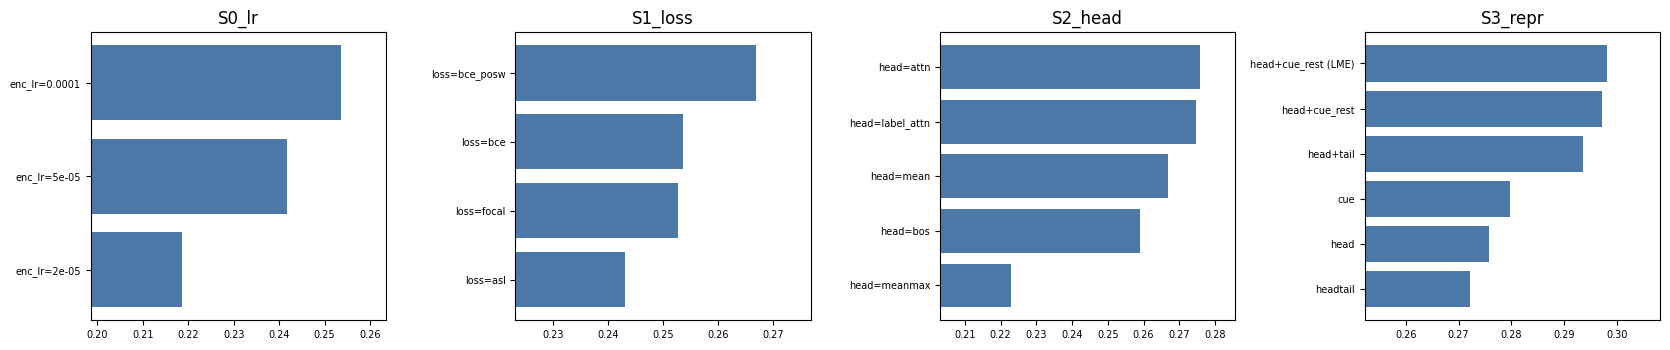

In [17]:
store = load_store()
allx = pd.DataFrame([{"name": n, "views": "+".join(e["rc"]["views"]), "agg": e["rc"]["view_agg"], "head": e["rc"]["head"], "loss": e["rc"]["loss"],
                      "enc_lr": e["rc"]["enc_lr"], "macro_F1@global": e["macro_f1_global"], "macro_AP": e["macro_ap"],
                      "macro_F1 per-label(CV)": e["macro_f1_perlabel_cv"], "micro_F1": e["micro_f1"], "train_min": e["train_minutes"],
                      "docs/s": e["train_docs_per_s"], "peak_GiB": e["peak_gib"]} for n, e in store.items()]).sort_values("macro_F1@global", ascending=False)
display(allx.round(4).reset_index(drop=True)); allx.to_csv(RUN_DIR / "all_experiments.csv", index=False)
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, len(STAGE_TABLES), figsize=(4.2 * max(1, len(STAGE_TABLES)), 3.6), squeeze=False)
    for ax, (k, df) in zip(axes[0], STAGE_TABLES.items()):
        d = df.sort_values("macro_F1@global"); ax.barh(d["variant"].str.replace("views=", "", regex=False).str.replace(" | chunk-logit LME", " (LME)", regex=False), d["macro_F1@global"], color="#4c78a8")
        ax.set_title(k); ax.set_xlim(max(0, d["macro_F1@global"].min() - 0.02), d["macro_F1@global"].max() + 0.01); ax.tick_params(labelsize=7)
    plt.tight_layout(); plt.show()
except Exception as e: print("plot skipped:", e)

## 14. S4 — post-hoc experiments on the winning model (no training needed)

Everything here is scored **out-of-fold (5-fold)** on the dev subset, so thresholds/calibrators/stackers are never judged on the data they were fitted on.

* **Global vs per-label vs shrunk thresholds** (precision/recall trade-off)
* **Top-1 fallback** (never return an empty statute set)
* **Calibration**: temperature, per-label Platt (reliability reported as ECE / Brier)
* **Label co-occurrence**: a linear stacker that re-scores each statute from all 100 logits

analysing dev logits of: S3:views=head+cue_rest (3000, 100)


,strategy,macro_f1,micro_f1,macro_precision,macro_recall,subset_acc,avg_pred,empty_rate,seconds
0,stacker -> per-label shrunk(100),0.2997,0.4188,0.2729,0.3565,0.0167,5.8560,0.0000,10.8095
1,per-label shrunk(100) + top1,0.2997,0.4056,0.2624,0.3733,0.0150,5.8583,0.0000,0.6282
2,per-label shrunk(300) + top1,0.2982,0.4052,0.2593,0.3763,0.0163,5.8130,0.0000,0.6432
3,global,0.2972,0.4026,0.2598,0.3780,0.0197,5.6347,0.0407,0.3118
4,global + top1,0.2970,0.4021,0.2578,0.3795,0.0207,5.6753,0.0000,0.3080
5,temperature -> global,0.2969,0.4022,0.2613,0.3727,0.0220,5.5143,0.0000,1.0192
6,per-label raw + top1,0.2954,0.3825,0.2759,0.3614,0.0093,6.3480,0.0000,0.5962
7,Platt -> per-label shrunk(100),0.2899,0.4190,0.2694,0.3360,0.0150,5.6127,0.0000,1.2744
8,stacker -> global,0.2864,0.4114,0.2495,0.3729,0.0077,7.1353,0.0000,10.5161
9,Platt -> global,0.2800,0.4126,0.2477,0.3568,0.0097,6.8730,0.0000,0.9866


,calibrator,ECE,Brier,macro_AP
0,raw,0.06117,0.04027,0.27988
1,temperature,0.03613,0.03835,0.27988
2,per-label Platt,0.00164,0.02832,0.27988
3,stacker (co-occurrence),0.00422,0.02866,0.26330


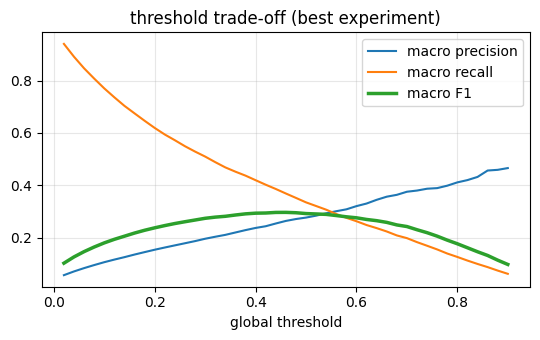


strongest statute co-occurrences in train (lift = observed/expected, count >= 50):
  statutes 20 & 28: lift  65.8  (together in 451 docs)
  statutes 15 & 16: lift  53.0  (together in 277 docs)
  statutes 29 & 49: lift  50.3  (together in 222 docs)
  statutes 49 & 50: lift  50.2  (together in 142 docs)
  statutes 29 & 50: lift  44.4  (together in 164 docs)
  statutes 64 & 86: lift  42.5  (together in 228 docs)
  statutes 23 & 25: lift  39.2  (together in 80 docs)
  statutes 29 & 36: lift  37.0  (together in 245 docs)
  statutes 21 & 47: lift  31.4  (together in 442 docs)
  statutes 21 & 53: lift  30.9  (together in 630 docs)
mean labels/doc = 3.70; docs with >=5 labels: 30.9%


In [18]:
best_entry = [e for e in load_store().values() if e["rc_key"] == rc_key(BEST_RC)]
best_entry = best_entry[0] if best_entry else max(load_store().values(), key=lambda e: e["macro_f1_global"])
z_best = np.load(logits_path(best_entry["name"])); y_best = Y_dev_sub
print("analysing dev logits of:", best_entry["name"], z_best.shape)

def strategy_table(y, z, K=5):
    rows, preds = [], {}
    for name, fn in STRATEGIES.items():
        t0 = time.time(); pr = crossfit(y, z, fn, K=K); preds[name] = pr
        rows.append(dict(strategy=name, **prf_summary(y, pr), seconds=time.time() - t0))
    return pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True), preds

S4_TABLE, S4_PREDS = strategy_table(y_best, z_best)
display(S4_TABLE.round(4))

# calibration quality (fit on one half, measure on the other)
h = len(z_best) // 2; zc_tr, zc_te, yc_tr, yc_te = z_best[:h], z_best[h:], y_best[:h], y_best[h:]
cal_rows = []
for nm, tf in [("raw", lambda q: q), ("temperature", fit_temperature(yc_tr, zc_tr)), ("per-label Platt", fit_platt(yc_tr, zc_tr)), ("stacker (co-occurrence)", fit_stacker(yc_tr, zc_tr))]:
    e_, b_ = ece_brier(yc_te, sigmoid(tf(zc_te))); cal_rows.append(dict(calibrator=nm, ECE=e_, Brier=b_, macro_AP=macro_ap(yc_te, sigmoid(tf(zc_te)))))
display(pd.DataFrame(cal_rows).round(5))

# precision / recall trade-off of one global threshold
try:
    import matplotlib.pyplot as plt
    ths = np.round(np.arange(0.02, 0.91, 0.02), 2); P, R, Fm = [], [], []
    for t in ths:
        s = prf_summary(y_best, (sigmoid(z_best) >= t).astype(np.uint8)); P.append(s["macro_precision"]); R.append(s["macro_recall"]); Fm.append(s["macro_f1"])
    plt.figure(figsize=(5.5, 3.5)); plt.plot(ths, P, label="macro precision"); plt.plot(ths, R, label="macro recall"); plt.plot(ths, Fm, label="macro F1", lw=2.5)
    plt.xlabel("global threshold"); plt.legend(); plt.grid(alpha=.3); plt.title("threshold trade-off (best experiment)"); plt.tight_layout(); plt.show()
except Exception as e: print("plot skipped:", e)

# label co-occurrence structure in the training labels
co = (Ytr.T.astype(np.float64) @ Ytr.astype(np.float64)); marg = np.diag(co).copy(); np.fill_diagonal(co, 0)
lift = co * len(Ytr) / np.maximum(np.outer(marg, marg), 1)
pairs = sorted([(lift[i, j], co[i, j], i, j) for i in range(NUM_LABELS) for j in range(i + 1, NUM_LABELS) if co[i, j] >= 50], reverse=True)[:10]
print("\nstrongest statute co-occurrences in train (lift = observed/expected, count >= 50):")
for l, c, i, j in pairs: print(f"  statutes {i:>2d} & {j:>2d}: lift {l:5.1f}  (together in {int(c)} docs)")
print(f"mean labels/doc = {Ytr.sum(1).mean():.2f}; docs with >=5 labels: {(Ytr.sum(1)>=5).mean()*100:.1f}%")

## 15. FINAL TRAINING — best recipe, full training set, early stopping on dev

* Trains on **all** `train.json` documents with the recipe selected above; evaluates on the **full dev set** after every epoch (macro-F1 at the best global threshold); keeps the best epoch, stops after `FINAL_PATIENCE` epochs without improvement.
* The number of planned epochs is capped so the LR schedule can finish inside `FINAL_TIME_BUDGET_H` (estimated from the measured throughput).
* Saves `final_best.pt` at every new best epoch and `final_last.pt` (with optimizer) every epoch → `RESUME_FINAL = True` continues an interrupted run.

In [19]:
FINAL_RC = dict(BEST_RC); FINAL_RC["views"] = tuple(FINAL_RC["views"])
FINAL_BEST_PT, FINAL_LAST_PT = RUN_DIR / "final_best.pt", RUN_DIR / "final_last.pt"
FINAL_DEV_LOGITS = RUN_DIR / "final_best_dev_logits.npy"; FINAL_HISTORY = RUN_DIR / "final_history.json"

final_train_idx = np.arange(Ntr) if FINAL_TRAIN_DOCS_LIMIT is None else np.sort(np.random.default_rng(SEED).permutation(Ntr)[:FINAL_TRAIN_DOCS_LIMIT])
final_dev_idx = np.arange(Ndv) if FINAL_TRAIN_DOCS_LIMIT is None else np.arange(min(Ndv, 512))
Y_final_dev = Ydv[final_dev_idx]

dps = best_entry["train_docs_per_s"]; edps = best_entry["eval_docs_per_s"]
est_epoch_s = len(final_train_idx) / dps + len(final_dev_idx) / edps
planned_epochs = int(max(1, min(FINAL_MAX_EPOCHS, (FINAL_TIME_BUDGET_H * 3600) // est_epoch_s)))
if SMOKE_TEST: planned_epochs = FINAL_MAX_EPOCHS
print("final recipe:", json.dumps(rc_norm(FINAL_RC)))
print(f"estimated {est_epoch_s/60:.0f} min / epoch  ->  planned epochs = {planned_epochs} (max {FINAL_MAX_EPOCHS}, patience {FINAL_PATIENCE})")

seed_everything(SEED)
final_model = build_model(FINAL_RC)
FT = build_training(final_model, FINAL_RC, len(final_train_idx), planned_epochs)
final_train_ds = LSIDataset("train", final_train_idx, FINAL_RC["views"]); final_dev_ds = LSIDataset("dev", final_dev_idx, FINAL_RC["views"])

history, best_f1, best_epoch, bad, start_epoch = [], -1.0, 0, 0, 1
if RESUME_FINAL and FINAL_LAST_PT.exists():
    ck = torch.load(FINAL_LAST_PT, map_location="cpu", weights_only=False)
    final_model.load_state_dict(ck["model"]); FT["opt"].load_state_dict(ck["opt"]); FT["sched"].load_state_dict(ck["sched"]); FT["scaler"].load_state_dict(ck["scaler"])
    history, best_f1, best_epoch, bad, start_epoch = ck["history"], ck["best_f1"], ck["best_epoch"], ck["bad"], ck["epoch"] + 1
    del ck; print(f"resumed after epoch {start_epoch-1}; best so far {best_f1:.4f} (epoch {best_epoch})")

run_start = time.time()
for epoch in range(start_epoch, planned_epochs + 1):
    ep0 = time.time()
    tr_loss, d = train_one_epoch(final_model, make_loader(final_train_ds, FT["mb"], True, SEED + epoch), FT, tag=f"final ep{epoch}/{planned_epochs}", log_frac=0.1)
    z_dev, _ = predict_logits(final_model, final_dev_ds, FT["mb"] * 2)
    m = evaluate_logits(Y_final_dev, z_dev)
    rec = dict(epoch=epoch, train_loss=tr_loss, **{k: m[k] for k in ["macro_f1_global", "best_global_thr", "macro_ap", "macro_f1_perlabel_cv", "micro_f1", "subset_acc", "macro_precision", "macro_recall", "bce"]},
               epoch_minutes=(time.time() - ep0) / 60); history.append(rec)
    print(f"\n=== epoch {epoch}: train loss {tr_loss:.4f} | dev macro-F1 {m['macro_f1_global']:.4f} @thr {m['best_global_thr']:.2f} | per-label(CV) {m['macro_f1_perlabel_cv']:.4f} | "
          f"macro-AP {m['macro_ap']:.4f} | micro-F1 {m['micro_f1']:.4f} | {rec['epoch_minutes']:.1f} min ===\n")
    if m["macro_f1_global"] > best_f1 + 1e-4:
        best_f1, best_epoch, bad = m["macro_f1_global"], epoch, 0
        torch.save({"model_state_dict": {k: v.detach().cpu() for k, v in final_model.state_dict().items()}, "epoch": epoch, "dev_macro_f1_global": best_f1}, FINAL_BEST_PT)
        np.save(FINAL_DEV_LOGITS, z_dev.astype(np.float32)); print(f"   new best epoch {epoch} saved -> {FINAL_BEST_PT}")
    else:
        bad += 1; print(f"   no improvement ({bad}/{FINAL_PATIENCE})")
    json.dump(history, open(FINAL_HISTORY, "w"), indent=1)
    torch.save({"model": final_model.state_dict(), "opt": FT["opt"].state_dict(), "sched": FT["sched"].state_dict(), "scaler": FT["scaler"].state_dict(),
                "history": history, "best_f1": best_f1, "best_epoch": best_epoch, "bad": bad, "epoch": epoch}, FINAL_LAST_PT)
    if bad >= FINAL_PATIENCE: print("early stopping."); break
print(f"\nfinal training finished: best epoch {best_epoch}, dev macro-F1 {best_f1:.4f}, wall time {(time.time()-run_start)/3600:.2f} h (this session)")
display(pd.DataFrame(history).round(4))

final recipe: {"views": ["head", "cue_rest"], "view_agg": "tokens", "head": "attn", "loss": "bce_posw", "enc_lr": 0.0001, "head_lr": 0.001, "llrd": 0.92, "wd": 0.01, "dropout": 0.1, "warmup": 0.06}
estimated 57 min / epoch  ->  planned epochs = 8 (max 10, patience 2)
   final ep1/8 534/5344 | loss 0.4834 | 13.5 docs/s
   final ep1/8 1068/5344 | loss 0.4379 | 13.5 docs/s
   final ep1/8 1602/5344 | loss 0.4083 | 13.5 docs/s
   final ep1/8 2136/5344 | loss 0.3900 | 13.5 docs/s
   final ep1/8 2670/5344 | loss 0.3775 | 13.5 docs/s
   final ep1/8 3204/5344 | loss 0.3682 | 13.5 docs/s
   final ep1/8 3738/5344 | loss 0.3605 | 13.5 docs/s
   final ep1/8 4272/5344 | loss 0.3536 | 13.5 docs/s
   final ep1/8 4806/5344 | loss 0.3479 | 13.5 docs/s
   final ep1/8 5340/5344 | loss 0.3429 | 13.5 docs/s
   final ep1/8 5344/5344 | loss 0.3429 | 13.5 docs/s

=== epoch 1: train loss 0.3429 | dev macro-F1 0.3189 @thr 0.45 | per-label(CV) 0.3390 | macro-AP 0.2958 | micro-F1 0.4210 | 56.8 min ===

   new best

,epoch,train_loss,macro_f1_global,best_global_thr,macro_ap,macro_f1_perlabel_cv,micro_f1,subset_acc,macro_precision,macro_recall,bce,epoch_minutes
0,1,0.3429,0.3189,0.45,0.2958,0.3390,0.4210,0.0153,0.2959,0.4135,0.1503,56.8056
1,2,0.2613,0.3558,0.54,0.3328,0.3692,0.4456,0.0364,0.3341,0.4304,0.1468,56.8345
2,3,0.1947,0.3702,0.50,0.3455,0.3795,0.4625,0.0424,0.3478,0.4248,0.1254,56.8535
3,4,0.1243,0.3741,0.53,0.3480,0.3827,0.4662,0.0492,0.3637,0.4052,0.1283,56.9144
4,5,0.0765,0.3826,0.45,0.3524,0.3848,0.4846,0.0606,0.3999,0.3826,0.1276,56.9126
5,6,0.0444,0.3794,0.36,0.3500,0.3807,0.4832,0.0640,0.3853,0.3883,0.1423,56.8328
6,7,0.0234,0.3779,0.32,0.3467,0.3801,0.4841,0.0735,0.4019,0.3682,0.1594,56.8004


## 16. Reload the best epoch, choose the post-processing on dev (out-of-fold), predict the test set, write the submission

The post-processing recipe (global / per-label-shrunk thresholds, top-1 fallback, calibration, stacker) is picked by **5-fold out-of-fold macro-F1 on the full dev set** and then refitted on all dev documents.

In [20]:
ck = torch.load(FINAL_BEST_PT, map_location="cpu", weights_only=False)
final_model.load_state_dict(ck["model_state_dict"]); final_model.eval(); best_epoch = ck["epoch"]; del ck
z_dev_final = np.load(FINAL_DEV_LOGITS); assert z_dev_final.shape == Y_final_dev.shape

POST_TABLE, POST_PREDS = strategy_table(Y_final_dev, z_dev_final, K=5)
print("post-processing options, out-of-fold on the full dev set:"); display(POST_TABLE.round(4))
POST_NAME = POST_TABLE.iloc[0]["strategy"]
post_predictor = STRATEGIES[POST_NAME](Y_final_dev, z_dev_final)         # refit on ALL dev documents
dev_oof_pred = POST_PREDS[POST_NAME]
print(f"\nchosen post-processing: {POST_NAME} | out-of-fold dev macro-F1 {POST_TABLE.iloc[0]['macro_f1']:.4f} | micro-F1 {POST_TABLE.iloc[0]['micro_f1']:.4f} | subset acc {POST_TABLE.iloc[0]['subset_acc']:.4f}")
base_row = POST_TABLE[POST_TABLE.strategy == "global"].iloc[0]
print(f"(plain global threshold would give macro-F1 {base_row['macro_f1']:.4f})")

# ---------------- test inference ----------------
test_ds = LSIDataset("test", np.arange(Nte), FINAL_RC["views"], with_labels=False)
t0 = time.time(); z_test, test_dps = predict_logits(final_model, test_ds, FT["mb"] * 2); infer_s = time.time() - t0
np.save(RUN_DIR / "test_logits.npy", z_test.astype(np.float32)); print(f"test inference: {Nte:,} docs in {infer_s/60:.1f} min ({test_dps:.1f} docs/s)")
test_pred = post_predictor(z_test)

# ---------------- submission ----------------
def write_submission(case_ids, pred_bin, path):
    out = []
    for i, cid in enumerate(case_ids):
        labs = sorted({int(j) for j in np.flatnonzero(pred_bin[i])})
        out.append({"id": cid, "pred": labs})
    assert len(out) == len(case_ids) == len({json.dumps(c) for c in case_ids}), "one unique object per test document"
    for o in out:
        assert all(isinstance(x, int) and 0 <= x < NUM_LABELS for x in o["pred"]) and len(o["pred"]) == len(set(o["pred"]))
    json.dump(out, open(path, "w")); return out

test_ids = ARR["test"]["ids"]
submission = write_submission(test_ids, test_pred, RUN_DIR / "submission.json")
if ON_KAGGLE: write_submission(test_ids, test_pred, WORK / "submission.json")
n_lab = np.array([len(o["pred"]) for o in submission])
print(f"submission written: {len(submission):,} objects | labels/doc mean {n_lab.mean():.2f}, min {n_lab.min()}, max {n_lab.max()} | empty {int((n_lab==0).sum())}")
print("first 3:", submission[:3]); print("train mean labels/doc for reference: %.2f" % Ytr.sum(1).mean())

# ---------------- final .pt (weights + everything needed to reproduce the predictions) ----------------
FINAL_PT = RUN_DIR / "lsi_encoder_full_ft_final.pt"
post = dict(name=POST_NAME, thresholds=np.asarray(post_predictor.thr).tolist(), calibrator=post_predictor.tf.params, ensure_at_least_one_label=True)
best_state = torch.load(FINAL_BEST_PT, map_location="cpu", weights_only=False)["model_state_dict"]
torch.save({"model_state_dict": best_state, "recipe": rc_norm(FINAL_RC), "encoder_config": asdict(cfg), "num_labels": NUM_LABELS, "label_ids": list(range(NUM_LABELS)),
            "best_epoch": best_epoch, "dev_metrics_best_epoch": history[best_epoch - 1] if history else None, "postprocess": post,
            "dev_oof_macro_f1_after_postprocess": float(POST_TABLE.iloc[0]["macro_f1"]), "max_seq_len": MAX_LEN, "content_tokens_per_view": CONTENT,
            "tokenizer_path": str(PHASE1_TOKENIZER_PATH), "phase1_checkpoint": str(PHASE1_CHECKPOINT_PATH), "experiment_1": "phase1 encoder + full fine-tuning"}, FINAL_PT)
del best_state; gc.collect()
print(f"final model saved: {FINAL_PT} ({FINAL_PT.stat().st_size/1024**2:.0f} MB)")
if ON_KAGGLE: print("also copy to /kaggle/working top level if needed:", WORK)

post-processing options, out-of-fold on the full dev set:


,strategy,macro_f1,micro_f1,macro_precision,macro_recall,subset_acc,avg_pred,empty_rate,seconds
0,per-label shrunk(100) + top1,0.3857,0.4874,0.3990,0.3896,0.0621,4.5399,0.0000,2.2579
1,per-label shrunk(300) + top1,0.3851,0.4880,0.3977,0.3886,0.0611,4.4947,0.0000,2.2672
2,per-label raw + top1,0.3838,0.4838,0.3959,0.3941,0.0598,4.6489,0.0000,2.2753
3,temperature -> global,0.3832,0.4843,0.3997,0.3836,0.0628,4.2333,0.0000,3.3755
4,Platt -> per-label shrunk(100),0.3831,0.4918,0.4033,0.3830,0.0628,4.5369,0.0000,4.6665
5,global + top1,0.3820,0.4837,0.3943,0.3865,0.0613,4.3317,0.0000,1.0625
6,global,0.3815,0.4839,0.3961,0.3843,0.0596,4.2945,0.0372,1.0693
7,stacker -> per-label shrunk(100),0.3793,0.4885,0.3853,0.3872,0.0547,4.5082,0.0000,34.8693
8,Platt -> global,0.3737,0.4852,0.3880,0.3988,0.0449,5.5964,0.0000,3.7034
9,stacker -> global,0.3735,0.4911,0.3720,0.3913,0.0511,4.7372,0.0000,33.9035



chosen post-processing: per-label shrunk(100) + top1 | out-of-fold dev macro-F1 0.3857 | micro-F1 0.4874 | subset acc 0.0621
(plain global threshold would give macro-F1 0.3815)
test inference: 13,019 docs in 5.1 min (42.4 docs/s)
submission written: 13,019 objects | labels/doc mean 4.47, min 1, max 22 | empty 0
first 3: [{'id': '100002997', 'pred': [5, 34, 37, 94]}, {'id': '100004477', 'pred': [5, 71, 81, 94]}, {'id': '1000086', 'pred': [94]}]
train mean labels/doc for reference: 3.70
final model saved: /kaggle/working/lsi_runs/lsi_encoder_full_ft_final.pt (532 MB)
also copy to /kaggle/working top level if needed: /kaggle/working


## 17. Analysis for the report (§10.5): which statutes are missed / confused, rare statutes, cost

In [21]:
y, pr = Y_final_dev, dev_oof_pred                   # out-of-fold predictions after the chosen post-processing
f1 = label_f1(y, pr); sup_tr = Ytr.sum(0); sup_dv = y.sum(0)
yb, pb = y.astype(bool), pr.astype(bool); tp = (yb & pb).sum(0); fp = (~yb & pb).sum(0); fn = (yb & ~pb).sum(0)
per_label = pd.DataFrame({"statute": np.arange(NUM_LABELS), "train_support": sup_tr, "dev_support": sup_dv, "precision": tp / np.maximum(tp + fp, 1),
                          "recall": tp / np.maximum(tp + fn, 1), "f1": f1, "FP": fp, "FN": fn})
per_label.to_csv(RUN_DIR / "final_per_label_metrics.csv", index=False)
per_label["support_quartile"] = pd.qcut(per_label["train_support"].rank(method="first"), 4, labels=["rarest 25%", "rare-mid", "common-mid", "most common 25%"])
print("macro-F1 by statute frequency (how rare statutes affect performance):"); display(per_label.groupby("support_quartile", observed=True)[["f1", "precision", "recall"]].mean().round(3))
print("worst statutes:"); display(per_label.sort_values("f1").head(12).round(3).reset_index(drop=True))
print("best statutes:");  display(per_label.sort_values("f1", ascending=False).head(8).round(3).reset_index(drop=True))
print("correlation between statute frequency and F1: %.3f" % np.corrcoef(np.log(sup_tr), f1)[0, 1])

# confusion: statute j missed (FN) in documents where statute k was predicted without being true
M = (yb & ~pb).T.astype(np.int64) @ (~yb & pb).astype(np.int64); np.fill_diagonal(M, 0)
top = np.dstack(np.unravel_index(np.argsort(-M.ravel())[:12], M.shape))[0]
print("\nmost common 'missed j while spurious k predicted' pairs:")
for j, k in top: print(f"  missed {j:>2d} / predicted-instead {k:>2d}: {M[j,k]:4d} docs   (train co-occurrence lift of the pair: {lift[j,k]:.1f})")
corr = np.corrcoef(np.log1p(M).ravel(), np.log1p(co).ravel())[0, 1]; print(f"confusion pairs vs. train co-occurrence correlation: {corr:.3f}")

# experiment comparison + cost
store = load_store(); rows = []
for n, e in store.items():
    rows.append({"experiment": n, "macro_F1@global": e["macro_f1_global"], "macro_AP": e["macro_ap"], "trainable_params_M": e["params_trainable"] / 1e6,
                 "train_docs/s": e["train_docs_per_s"], "eval_docs/s": e["eval_docs_per_s"], "peak_GPU_GiB": e["peak_gib"], "train_min": e["train_minutes"]})
cost = pd.DataFrame(rows).sort_values("macro_F1@global", ascending=False)
n_params_final = sum(p.numel() for p in final_model.parameters())
print(f"\nfinal model: {n_params_final/1e6:.1f} M parameters (all trainable), fp32 checkpoint {FINAL_PT.stat().st_size/1024**2:.0f} MB, "
      f"test inference {test_dps:.1f} docs/s, views per document = {len(FINAL_RC['views'])}")
display(cost.round(3).head(20).reset_index(drop=True))

# automatic headline summary
print("\n================ SUMMARY FOR THE REPORT ================")
for stage, df in STAGE_TABLES.items():
    d = df.sort_values("macro_F1@global", ascending=False); b, w = d.iloc[0], d.iloc[-1]
    print(f"{stage:9s}: best '{b['variant']}' {b['macro_F1@global']:.4f}  | worst '{w['variant']}' {w['macro_F1@global']:.4f} | spread {b['macro_F1@global']-w['macro_F1@global']:.4f}")
print(f"post-processing: global {base_row['macro_f1']:.4f} -> '{POST_NAME}' {POST_TABLE.iloc[0]['macro_f1']:.4f} (out-of-fold, full dev)")
print(f"final dev macro-F1 at best epoch ({best_epoch}), single global threshold: {best_f1:.4f}; earlier 4-epoch baseline (512-token head, BCE): 0.2610")

macro-F1 by statute frequency (how rare statutes affect performance):


,f1,precision,recall
support_quartile,,,
rarest 25%,0.281,0.341,0.254
rare-mid,0.357,0.386,0.339
common-mid,0.398,0.390,0.417
most common 25%,0.507,0.479,0.549


worst statutes:


,statute,train_support,dev_support,precision,recall,f1,FP,FN,support_quartile
0,8,349,92,0.273,0.065,0.105,16,86,rarest 25%
1,0,343,86,0.163,0.093,0.119,41,78,rarest 25%
2,32,385,99,0.125,0.162,0.141,112,83,rarest 25%
3,52,1084,272,0.120,0.202,0.151,403,217,common-mid
4,40,543,152,0.142,0.171,0.155,157,126,rare-mid
5,2,367,98,0.191,0.133,0.157,55,85,rarest 25%
6,99,674,176,0.163,0.159,0.161,144,148,rare-mid
7,82,604,156,0.146,0.199,0.168,182,125,rare-mid
8,25,287,72,0.203,0.181,0.191,51,59,rarest 25%
9,76,530,142,0.180,0.204,0.191,132,113,rare-mid


best statutes:


,statute,train_support,dev_support,precision,recall,f1,FP,FN,support_quartile
0,28,602,151,0.786,0.828,0.806,34,26,rare-mid
1,34,10380,2596,0.770,0.821,0.795,636,465,most common 25%
2,81,1321,346,0.772,0.743,0.757,76,89,common-mid
3,20,487,122,0.770,0.713,0.740,26,35,rare-mid
4,94,3835,958,0.730,0.697,0.713,247,290,most common 25%
5,29,497,125,0.725,0.592,0.652,28,51,rare-mid
6,36,569,142,0.652,0.634,0.643,48,52,rare-mid
7,5,11730,2936,0.535,0.767,0.630,1954,685,most common 25%


correlation between statute frequency and F1: 0.548

most common 'missed j while spurious k predicted' pairs:
  missed 12 / predicted-instead  5:  189 docs   (train co-occurrence lift of the pair: 0.7)
  missed 14 / predicted-instead  5:  168 docs   (train co-occurrence lift of the pair: 0.9)
  missed 13 / predicted-instead  5:  165 docs   (train co-occurrence lift of the pair: 0.7)
  missed 39 / predicted-instead 43:  152 docs   (train co-occurrence lift of the pair: 1.6)
  missed 39 / predicted-instead  5:  148 docs   (train co-occurrence lift of the pair: 1.4)
  missed 39 / predicted-instead 97:  138 docs   (train co-occurrence lift of the pair: 1.2)
  missed 10 / predicted-instead  5:  123 docs   (train co-occurrence lift of the pair: 1.0)
  missed 46 / predicted-instead 43:  119 docs   (train co-occurrence lift of the pair: 2.0)
  missed 43 / predicted-instead  5:  112 docs   (train co-occurrence lift of the pair: 1.5)
  missed  5 / predicted-instead 97:  111 docs   (train co-occu

,experiment,macro_F1@global,macro_AP,trainable_params_M,train_docs/s,eval_docs/s,peak_GPU_GiB,train_min
0,S3:views=head+cue_rest | chunk-logit LME,0.298,0.260,139.363,13.509,42.253,7.650,19.881
1,S3:views=head+cue_rest,0.297,0.261,139.363,13.505,42.427,7.650,19.887
2,S3:views=head+tail,0.294,0.257,139.363,13.505,42.350,7.650,19.886
3,S3:views=cue,0.280,0.234,139.363,26.061,84.173,7.650,10.305
4,S2:head=attn,0.276,0.233,139.363,26.087,83.606,7.650,10.295
5,S2:head=label_attn,0.275,0.239,139.388,26.048,84.327,7.648,10.310
6,S3:views=headtail,0.272,0.234,139.363,26.069,84.148,7.650,10.302
7,S1:loss=bce_posw,0.267,0.228,139.166,26.129,83.841,7.643,10.279
8,S2:head=bos,0.259,0.220,139.166,26.219,84.639,7.643,10.243
9,S0:enc_lr=0.0001,0.254,0.233,139.166,26.223,84.860,7.643,10.242



================ SUMMARY FOR THE REPORT ================
S0_lr    : best 'enc_lr=0.0001' 0.2536  | worst 'enc_lr=2e-05' 0.2185 | spread 0.0350
S1_loss  : best 'loss=bce_posw' 0.2668  | worst 'loss=asl' 0.2431 | spread 0.0237
S2_head  : best 'head=attn' 0.2757  | worst 'head=meanmax' 0.2230 | spread 0.0527
S3_repr  : best 'views=head+cue_rest | chunk-logit LME' 0.2981  | worst 'views=headtail' 0.2722 | spread 0.0259
post-processing: global 0.3815 -> 'per-label shrunk(100) + top1' 0.3857 (out-of-fold, full dev)
final dev macro-F1 at best epoch (5), single global threshold: 0.3826; earlier 4-epoch baseline (512-token head, BCE): 0.2610
